<img src="https://images.seeklogo.com/logo-png/28/1/u-cayetano-heredia-logo-png_seeklogo-289967.png" alt="LOGO UPCH" width=250 align="right">

<br>
<h1><font color="#7F000E" size=5>UNIVERSIDAD PERUANA CAYETANO HEREDIA</font></h1>
<h1><font color="#7F000E" size=6>SEÑALES BIOMÉDICAS</font></h1>
<h1><font color="#7F000E" size=4>LAB 12 —Tratamiento de la señal EEG, ritmos cerebrales, filtro ICA y extracción de características</font></h1>
<br>
<br>
<div style="text-align:right">
<font color="#7F000E" size=3> Curso: Introducción a las Señales Biomédicas</font><br>
<font color="#7F000E" size=3> Registros: 4 archivos EEG de un participante (BITalino, 25/09/2026)</font><br>
</div>

| Campo | Completar |
|---|---|
| **Nombre del estudiante** | Miguel Tello, Jairo Villalobos, Mateo Torres, Mauricio Zenteno |
| **Código** | ✍️ |
| **Grupo** | 11 |
| **Fecha** | 06/11/2026 |

> **Material base:** clase *Tratamiento de señal EEG* (Mg. Lewis De La Cruz) · Ejemplo de MNE-Python [*Removing muscle ICA components*](https://mne.tools/stable/auto_examples/preprocessing/muscle_ica.html) · Laboratorio de adquisición de EEG con BITalino.

## 📌 Resumen de nuestros resultados (grupo 11)

| Aspecto | Resultado |
|---|---|
| Archivos | 4 registros de 1 canal, grabados a **1000 Hz** y diezmados a **100 Hz** para el análisis; 31–178 s; sin paquetes perdidos |
| Dispositivo | Un solo BITalino (**2A:08**) para los 4 registros |
| Interferencia | Pico de **60 Hz** en la señal original (4.7 a 88 veces sobre sus vecinos). Al diezmar, el filtro antialiasing lo quita y **no aparece alias en 40 Hz** |
| Saturación | preguntas complejas **29.4 %** · basal 6.4 % · música suave 3.2 % · música fuerte 2.5 % |
| Banda dominante | **Alfa** (pico en 8.5 Hz) en la basal y en las dos músicas; la alfa baja en la segunda mitad del registro basal (apertura/cierre de ojos) |
| ICA de un canal (Wavelet-ICA) | Solo corrige 2 componentes en preguntas complejas (2.2 % de la varianza); en los demás no cambia nada |
| Clasificación de 4 condiciones | Mejor F1 = **0.320** (Árbol de Decisión); azar = 0.25. Con tan pocas épocas válidas (3 en preguntas complejas) **no se puede reconocer la condición** |

<a id="indice"></a>
# 📑 Índice de contenido

> 💡 En Colab también puedes navegar con el panel **"Índice"** (ícono ☰ de la barra izquierda).

**[Introducción](#intro)** — ¿Qué haremos? · El EEG en una página · Nuestros datos · Agenda

**[⚙️ Configuración](#config)**

**[🅰️ PARTE A — Conociendo nuestros datos](#parteA)** *(≈ 15 min)*
- [A.1 Subir los archivos e inventario automático](#A1)
- [A.2 Lectura, conversión a µV y saturación](#A2)
- [A.3 Primer vistazo: las señales en el tiempo](#A3)
- [A.4 Primer vistazo al espectro: ¿y ese pico en 40 Hz?](#A4)
- [A.5 Control de calidad automático](#A5)
- [A.6 Conclusiones de la Parte A](#A6)

**[🅱️ PARTE B — Tratamiento y extracción de características](#parteB)** *(≈ 40 min)*
- [B.1 El pipeline de procesamiento](#B1)
- [B.2 Filtrado](#B2)
- [B.3 Ritmos cerebrales: delta, theta, alfa, beta y gamma](#B3)
- [B.4 Filtro ICA: separar el cerebro de los artefactos](#B4)
- [B.5 Normalización y segmentación en épocas](#B5)
- [B.6 Extracción de características](#B6)
- [B.7 La tabla de características](#B7)
- [B.8 Clasificación y una advertencia importante](#B8)
- [B.9 Conclusiones de la Parte B](#B9)

**[📝 Cuestionario final: experimenta con tus datos](#cuestionario)** *(≈ 5 min o como tarea)*

**[📦 Entregables y referencias](#entregables)**

<a id="intro"></a>
# Introducción

## 🎯 ¿Qué haremos hoy?

**Objetivo: limpiar la señal EEG, analizar sus ritmos cerebrales y extraer características que permitan distinguir el estado del participante.**

Seguiremos el pipeline de la clase:

```
Señal fisiológica → Filtrado → Limpieza (ICA) → Preprocesamiento (normalización) → Extracción de características → Ingeniería de características
```

## 🧠 El EEG en una página

**¿Qué es?** El electroencefalograma es la actividad eléctrica registrada en el cuero cabelludo. La generan los **potenciales post-sinápticos** de grandes poblaciones de neuronas de la corteza cerebral que se activan de forma **sincronizada**.

**¿Qué tan grande es?** Muy pequeña: **20–100 µV** en el cuero cabelludo, unas **10 a 50 veces menos** que el ECG. Por eso el EEG es tan sensible al ruido y a los artefactos.

**Ritmos cerebrales.** El EEG se describe por **bandas de frecuencia**, y cada una se asocia a estados distintos:

| Banda | Frecuencia | Estado asociado |
|---|---|---|
| **Delta (δ)** | 0.5 – 4 Hz | Sueño profundo |
| **Theta (θ)** | 4 – 8 Hz | Somnolencia, meditación profunda |
| **Alfa (α)** | 8 – 13 Hz | Relajación con **ojos cerrados**; disminuye al abrir los ojos |
| **Beta (β)** | 13 – 30 Hz | Alerta, concentración, ojos abiertos |
| **Gamma (γ)** | > 30 Hz | Procesamiento cognitivo complejo; muy contaminada por actividad muscular |

> 📖 **Definición fácil:** imagina el EEG como el sonido de una orquesta. Cada banda es una sección de instrumentos: los contrabajos (delta) tocan lento y grave; los violines (beta, gamma), rápido y agudo. Analizar bandas es medir **qué tan fuerte suena cada sección**.

**Artefactos.** Son señales que **no vienen del cerebro** pero aparecen en el registro:

| Artefacto | Origen | Cómo se ve |
|---|---|---|
| **Parpadeo / movimiento ocular** | El ojo es un dipolo eléctrico; se mueve cerca de Fp1/Fp2 | Ondas lentas y grandes (< 4 Hz) |
| **Muscular (EMG)** | Músculos temporal, masetero y frontal (masticar, apretar) | Actividad rápida y "peluda" (> 20 Hz) |
| **Red eléctrica** | Instalación eléctrica (Perú: 60 Hz) | Oscilación de frecuencia fija |

## 🫀 Nuestros datos

Un participante registró su EEG con BITalino usando una **derivación frontal**: electrodo positivo en **Fp1**, negativo en **Fp2** y referencia en **O2**. Es **un solo canal**.

**Nuestros registros (grupo 11, 25/09/2026):**

| Archivo | Condición | Duración aprox. |
|---|---|---|
| `Linea_basal_y_apertura_cierre_de_ojos_eeg.txt` | Línea basal en reposo y luego apertura/cierre de ojos (en un solo archivo) | 3 min |
| `preguntas_complejas_eeg.txt` | Respondiendo preguntas complejas (tarea mental) | 3 min |
| `musica_suave_eeg.txt` | Escuchando música suave | 30 s |
| `musica_fuerte_eeg.txt` | Escuchando música fuerte | 30 s |

Nuestros archivos se grabaron a **1000 Hz** (la guía asume 100 Hz), así que en A.2 los diezmamos a 100 Hz.

El cuaderno reconoce la condición por palabras clave en el nombre del archivo. Las cambiamos a las de nuestros archivos: `basal`, `pregunt`, `suave`, `fuerte`. No importan las mayúsculas.

## ⏱️ Agenda (60 min)

| Parte | Contenido | Minutos |
|---|---|---:|
| Configuración | Librerías y carga de archivos | 0 – 5 |
| **A** | Conocer los datos: inventario, saturación, espectro y calidad | 5 – 20 |
| **B** | Filtrado → bandas → ICA → épocas → características → clasificación | 20 – 55 |
| Cuestionario | Experimentos con tus datos | 55 – 60 (o tarea) |

<a id="config"></a>
# ⚙️ Configuración

| Librería | Para qué la usamos |
|---|---|
| `numpy`, `pandas` | Números y tablas |
| `matplotlib` | Gráficas |
| `scipy.signal` | Filtros y espectro (método de Welch) |
| `pywt` (PyWavelets) | Descomposición wavelet (para el ICA de un canal) |
| `scikit-learn` | FastICA, clasificadores y validación |

In [1]:
# PyWavelets no siempre viene en Colab: se instala solo si falta
try:
    import pywt
except ImportError:
    !pip install -q PyWavelets
    import pywt

import os, re, glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import skew, kurtosis
from sklearn.decomposition import FastICA

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (14, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.titleweight": "bold", "font.size": 11})
np.random.seed(0)

# Nuestras 4 condiciones (grupo 11)
ORDEN = ["basal", "preguntas_complejas", "musica_suave", "musica_fuerte"]
COLOR = {"basal": "tab:blue", "preguntas_complejas": "tab:red",
         "musica_suave": "tab:green", "musica_fuerte": "tab:purple"}
BANDAS = {"delta": (1, 4), "theta": (4, 8), "alfa": (8, 13), "beta": (13, 30), "gamma": (30, 45)}
COLOR_BANDA = {"delta": "#4C72B0", "theta": "#55A868", "alfa": "#C44E52", "beta": "#8172B2", "gamma": "#CCB974"}
print("✅ Librerías listas | PyWavelets", pywt.__version__)

✅ Librerías listas | PyWavelets 1.8.0


---
<a id="parteA"></a>
# 🅰️ PARTE A — Conociendo nuestros datos *(≈ 15 min)*

> **Idea central:** antes de aplicar ICA o calcular características, **revisamos los datos**. En el EEG esto es todavía más importante que en el ECG: la señal es diminuta y cualquier problema de adquisición puede ser más grande que el propio cerebro.

[⬆️ Volver al índice](#indice)

<a id="A1"></a>
## A.1 Subir los archivos e inventario automático

Ejecuta la celda. En Colab se abrirá un botón para **subir tus archivos `.txt`**; puedes seleccionarlos todos a la vez. El cuaderno:
1. Busca todos los `.txt` cuyo sensor sea **EEG** (lo lee en la cabecera).
2. Deduce la **condición** a partir del nombre del archivo.

> Si no hay archivos, se generan **registros simulados** solo para poder recorrer el cuaderno.

In [2]:
def condicion_desde_nombre(nombre):
    n = nombre.lower()
    # nombres de nuestros archivos: linea basal (con apertura/cierre de ojos), preguntas complejas, musica suave y fuerte
    if "basal" in n:                       return "basal"
    if "pregunt" in n:                     return "preguntas_complejas"
    if "suave" in n:                       return "musica_suave"
    if "fuerte" in n:                      return "musica_fuerte"
    return os.path.splitext(os.path.basename(n))[0]

def leer_cabecera(ruta):
    with open(ruta, "r", encoding="utf-8", errors="ignore") as f:
        lineas = [f.readline() for _ in range(3)]
    return list(json.loads(lineas[1].lstrip("# ").strip()).values())[0]

def buscar_archivos():
    filas = []
    for ruta in sorted(glob.glob("*.txt")):
        try:
            meta = leer_cabecera(ruta)
        except Exception:
            continue
        if any("EEG" in s.upper() for s in meta.get("sensor", [])):
            filas.append({"archivo": ruta, "condicion": condicion_desde_nombre(ruta)})
    return pd.DataFrame(filas, columns=["archivo", "condicion"])

inventario = buscar_archivos()
if len(inventario) == 0:
    try:
        from google.colab import files
        print("📤 Sube tus archivos .txt de OpenSignals (selecciónalos todos a la vez):")
        files.upload()
        inventario = buscar_archivos()
    except ImportError:
        pass

MODO_DEMO = inventario["condicion"].nunique() < 2 if len(inventario) else True
print("Modo:", "⚠️ DEMOSTRACIÓN (datos simulados)" if MODO_DEMO else "✅ datos reales del grupo")

Modo: ✅ datos reales del grupo


In [3]:
# ---- Solo en modo demostración: genera 3 registros EEG simulados ----
def generar_eeg_demo(ruta, alfa, beta, parpadeos, emg, dur=60, fs=100, semilla=0):
    rng = np.random.default_rng(semilla)
    t = np.arange(int(dur * fs)) / fs
    x = np.cumsum(rng.standard_normal(len(t))) * 0.05                     # fondo 1/f
    x = signal.detrend(x) + 1.5 * rng.standard_normal(len(t))
    def ritmo(lo, hi):                                                   # ruido filtrado: ritmo "ancho", no una línea
        b, a = signal.butter(4, [lo, hi], "bandpass", fs=fs)
        r = signal.filtfilt(b, a, rng.standard_normal(len(t)))
        return r / r.std()
    x += alfa * ritmo(8, 12) + beta * ritmo(15, 25)
    for tp in rng.uniform(1, dur - 1, parpadeos):                        # parpadeos
        x += 25 * np.exp(-((t - tp)**2) / (2 * 0.08**2))
    if emg:                                                              # ráfagas musculares
        env = (np.sin(2*np.pi*0.8*t) > 0.3).astype(float)
        b, a = signal.butter(4, [20, 45], "bandpass", fs=fs)
        x += emg * env * signal.lfilter(b, a, rng.standard_normal(len(t)))
    adc = np.clip(np.round((x / 1e6 * 41782 / 3.3 + 0.5) * 1024), 0, 1023).astype(int)
    meta = {"demo": {"sensor": ["EEGBITREV"], "column": ["nSeq", "I1", "I2", "O1", "O2", "A4"], "label": ["A4"],
                     "sampling rate": fs, "resolution": [4, 1, 1, 1, 1, 10], "date": "DEMO", "time": "00:00:00",
                     "device name": "DEMO"}}
    with open(ruta, "w") as f:
        f.write("# OpenSignals Text File Format\n# " + json.dumps(meta) + "\n# EndOfHeader\n")
        f.writelines(f"{i % 16}\t0\t0\t0\t0\t{v}\t\n" for i, v in enumerate(adc))

if MODO_DEMO:
    generar_eeg_demo("DEMO_basal.txt", alfa=4, beta=0.5, parpadeos=0, emg=0, semilla=1)
    generar_eeg_demo("DEMO_ojos_abiertos.txt", alfa=1, beta=1.5, parpadeos=15, emg=0, semilla=2)
    generar_eeg_demo("DEMO_parpadeo_masticacion.txt", alfa=1, beta=1, parpadeos=50, emg=6, semilla=3)
    inventario = buscar_archivos()

inventario["orden"] = inventario["condicion"].map(lambda c: ORDEN.index(c) if c in ORDEN else 99)
inventario = inventario.sort_values(["orden", "archivo"]).drop(columns="orden").reset_index(drop=True)
print(f"Se encontraron {len(inventario)} archivos de EEG:")
display(inventario)

Se encontraron 4 archivos de EEG:


,archivo,condicion
0,Linea_basal_y_apertura_cierre_de_ojos_eeg.txt,basal
1,preguntas_complejas_eeg.txt,preguntas_complejas
2,musica_suave_eeg.txt,musica_suave
3,musica_fuerte_eeg.txt,musica_fuerte


<a id="A2"></a>
## A.2 Lectura, conversión a µV y saturación

La función `leer_eeg` lee la cabecera de cada archivo (frecuencia de muestreo, resolución, dispositivo, hora) y convierte las cuentas del ADC a **microvoltios** con la fórmula del sensor EEG de BITalino:

$$
EEG_{\mu V} = \frac{\left(\dfrac{ADC}{2^{n}} - \dfrac{1}{2}\right) \cdot V_{CC}}{G_{EEG}} \times 10^{6}, \qquad V_{CC}=3.3\,V,\; G_{EEG}=41\,782,\; n = 10\ \text{bits}
$$

La ganancia es enorme (41 782, frente a 1 100 del ECG), porque la señal es diminuta. Consecuencias:
- **Rango medible:** apenas **±39.5 µV**. Un parpadeo fuerte o un movimiento **satura** el conversor fácilmente.
- **Resolución:** 1 cuenta del ADC equivale a **0.077 µV**.

**Nuestro caso:** nuestros archivos se grabaron a **1000 Hz** (la guía está pensada para 100 Hz). Como las bandas que nos interesan llegan solo hasta 45 Hz, **diezmamos las señales a 100 Hz** con `signal.decimate`, que primero aplica un filtro antialiasing y después se queda con 1 de cada 10 muestras. Así podemos usar el mismo pipeline (wavelets, épocas, etc.) sin cambiar los parámetros. Para contar la saturación usamos la señal original de 1000 Hz.

**Saturación:** cuando la señal supera el rango, el ADC se "pega" en su mínimo (0) o en su máximo. En estos registros el valor máximo que alcanza el ADC es **1018** (no 1023), así que contamos como saturadas las muestras en **0** o **≥ 1018**.

In [4]:
def formato_hora(texto):
    try:
        return ":".join(f"{int(p):02d}" for p in str(texto).split(".")[0].split(":"))
    except ValueError:
        return str(texto)

def leer_eeg(ruta):
    meta = leer_cabecera(ruta)
    columnas, sensores, etiquetas = meta["column"], meta.get("sensor", []), meta.get("label", [])
    canal = next((e for s, e in zip(sensores, etiquetas) if "EEG" in s.upper()), etiquetas[0])
    idx = columnas.index(canal)
    n_bits = meta["resolution"][idx]
    datos = pd.read_csv(ruta, sep=r"\s+", comment="#", header=None).iloc[:, :len(columnas)]
    adc = datos.iloc[:, idx].to_numpy(dtype=float)
    nseq = datos.iloc[:, 0].to_numpy(dtype=int)
    saturada = (adc <= 0) | (adc >= 2**n_bits - 6)        # rieles del ADC: 0 y ~1018
    fs = int(meta["sampling rate"])
    eeg = ((adc / 2**n_bits) - 0.5) * 3.3 / 41782 * 1e6
    # Nuestros registros están a 1000 Hz. Los bajamos a 100 Hz (FS_TRABAJO) para usar el mismo pipeline de la guía.
    # decimate() aplica antes un filtro antialiasing, así que los 60 Hz de la red se eliminan y NO aparecen en 40 Hz.
    q = fs // FS_TRABAJO
    n = (len(eeg) // q) * q
    eeg_d = signal.decimate(eeg[:n], q, ftype="iir", zero_phase=True) if q > 1 else eeg
    sat_d = saturada[:n].reshape(-1, q).any(axis=1) if q > 1 else saturada   # bloque saturado si alguna muestra lo estaba
    return {"adc": adc, "eeg_uV": eeg_d, "eeg_uV_orig": eeg, "fs_orig": fs, "fs": FS_TRABAJO,
            "saturada": sat_d, "sat_orig": saturada, "canal": canal, "bits": n_bits,
            "dispositivo": str(meta.get("device name", "-"))[-5:], "hora": formato_hora(meta.get("time", "-")),
            "perdidos": int(np.sum((np.diff(nseq) % 16) != 1))}

FS_TRABAJO = 100     # Hz, frecuencia con la que trabajamos después de diezmar

senales, filas = {}, []
for _, fila in inventario.iterrows():
    r = leer_eeg(fila.archivo)
    senales[fila.archivo] = r
    seg_sat = np.unique((np.flatnonzero(r["sat_orig"]) / r["fs_orig"]).astype(int))
    filas.append({"archivo": fila.archivo, "condición": fila.condicion, "dispositivo": r["dispositivo"],
                  "hora": r["hora"], "duración (s)": round(len(r["adc"]) / r["fs_orig"], 1), "Fs original (Hz)": r["fs_orig"], "Fs (Hz)": r["fs"],
                  "paquetes perdidos": r["perdidos"], "muestras saturadas": int(r["sat_orig"].sum()),
                  "% saturado": round(100 * r["sat_orig"].mean(), 2),
                  "segundos con saturación": ", ".join(map(str, seg_sat[:12])) + (" ..." if len(seg_sat) > 12 else "")})
tabla_lectura = pd.DataFrame(filas).sort_values("hora").reset_index(drop=True)
FS = int(tabla_lectura["Fs (Hz)"].iloc[0])
assert (tabla_lectura["Fs (Hz)"] == FS).all(), "Todos los archivos deben tener la misma frecuencia de muestreo."
print(f"Fs original: {tabla_lectura['Fs original (Hz)'].iloc[0]} Hz → diezmada a {FS} Hz (Nyquist = {FS/2:.0f} Hz)")
display(tabla_lectura)

Fs original: 1000 Hz → diezmada a 100 Hz (Nyquist = 50 Hz)


,archivo,condición,dispositivo,hora,duración (s),Fs original (Hz),Fs (Hz),paquetes perdidos,muestras saturadas,% saturado,segundos con saturación
0,Linea_basal_y_apertura_cierre_de_ojos_eeg.txt,basal,2A:08,15:19:57,177.0,1000,100,0,11292,6.38,"8, 9, 25, 26, 45, 56, 59, 65, 67, 85, 86, 87 ..."
1,preguntas_complejas_eeg.txt,preguntas_complejas,2A:08,15:23:34,178.3,1000,100,0,52420,29.39,"8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20 ..."
2,musica_suave_eeg.txt,musica_suave,2A:08,15:28:07,30.8,1000,100,0,990,3.22,"7, 9, 12, 15, 18, 21"
3,musica_fuerte_eeg.txt,musica_fuerte,2A:08,15:29:04,30.9,1000,100,0,785,2.54,"0, 4, 8, 12, 14, 16, 17, 20"


### ✍️ Pregunta A.1
1. Mira la columna **hora** (la tabla está ordenada cronológicamente). ¿En qué orden se hicieron las grabaciones? ¿Coincide con el protocolo?
2. Mira la columna **dispositivo**. ¿Se usó siempre el mismo BITalino?
3. ¿Qué archivos tienen saturación? Según la columna *segundos con saturación*, ¿está repartida por todo el registro o concentrada en algún momento?
4. La frecuencia de muestreo es **100 Hz**. ¿Hasta qué frecuencia podemos analizar? ¿Qué pasa con la banda gamma?

**Respuesta A.1**

1. El orden fue: línea basal con apertura/cierre de ojos (15:19:57) → preguntas complejas (15:23:34) → música suave (15:28:07) → música fuerte (15:29:04). Sí coincide con nuestro protocolo. Las dos músicas se grabaron casi seguidas, con menos de 1 min de diferencia.
2. Sí, los cuatro registros se hicieron con el mismo BITalino, el que termina en **2A:08**. A diferencia del grupo de la guía, no tenemos el problema de los dos equipos.
3. Los cuatro archivos tienen saturación:
   - **preguntas complejas: 29.39 %**. Satura casi todo el tiempo desde el segundo 8 (8, 10, 11, 12, 13...), o sea, está repartida por todo el registro.
   - **basal: 6.38 %**. Hay eventos sueltos (8, 9, 25, 26, 45...), pero aumentan desde el segundo ~85, que es cuando empieza la parte de abrir y cerrar los ojos.
   - **música suave: 3.22 %** (segundos 7, 9, 12, 15, 18, 21) y **música fuerte: 2.54 %** (0, 4, 8, 12, 14...). Son eventos cortos y separados.
4. Grabamos a **1000 Hz**, así que en la señal original se podría analizar hasta 500 Hz (Nyquist). Pero para el análisis la diezmamos a **100 Hz**, entonces el límite queda en **50 Hz**. Con el pasa-banda hasta 45 Hz, la **gamma solo se ve entre 30 y 45 Hz**, igual que en la guía. Como el diezmado usa un filtro antialiasing, lo que está por encima de ~40 Hz se atenúa antes de bajar la frecuencia, así que no se "pliega" en la banda que analizamos.

<a id="A3"></a>
## A.3 Primer vistazo: las señales en el tiempo

Graficamos **10 segundos** de cada registro, **sin filtrar** (solo se resta la media). Las líneas punteadas marcan el **rango del sensor** (±39.5 µV).

> **¿Qué buscar?** Señales que tocan los límites (saturación), ondas lentas grandes (parpadeos), tramos "peludos" de alta frecuencia (músculo) y diferencias de amplitud entre registros.

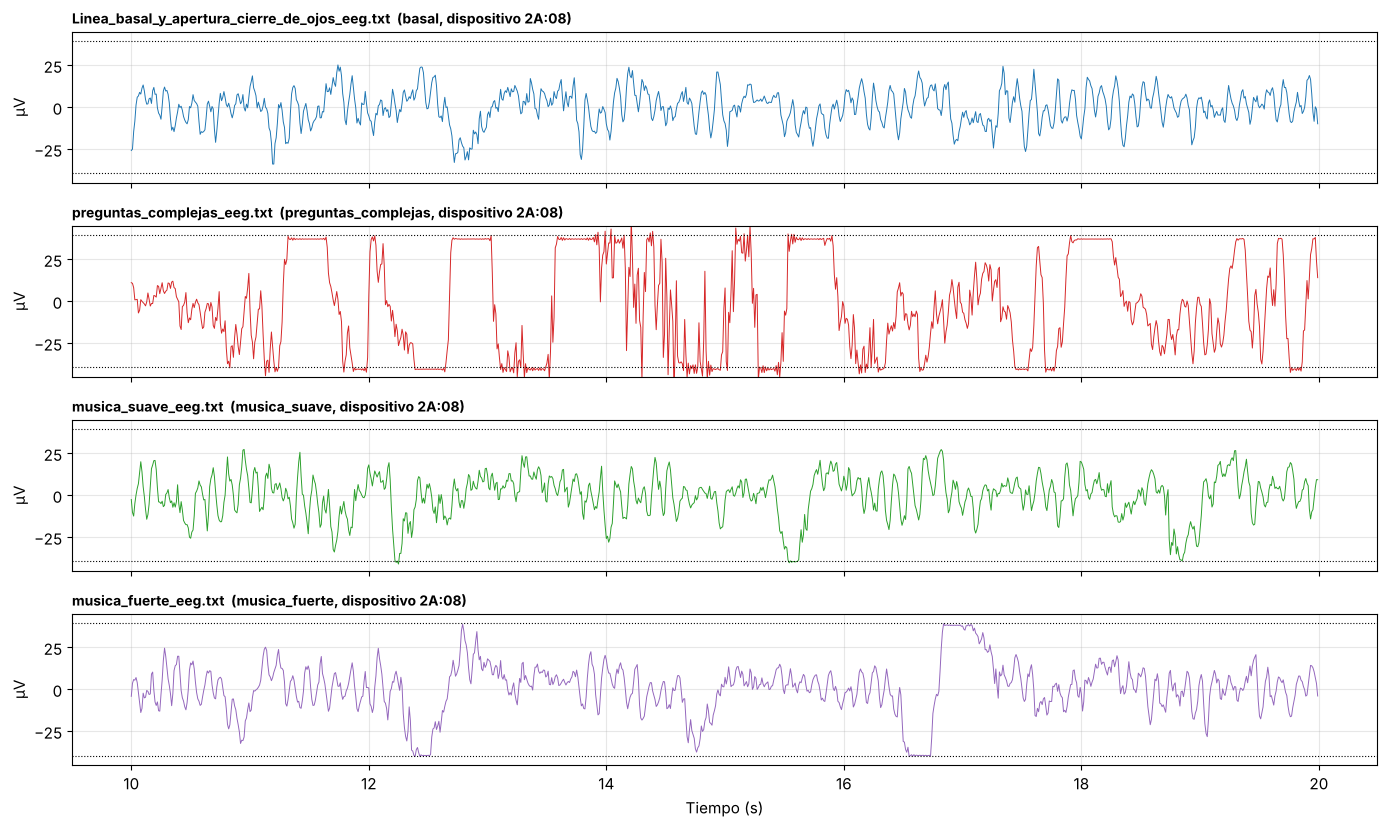

In [5]:
RANGO_UV = 0.5 * 3.3 / 41782 * 1e6      # ±39.5 µV
T0, DUR = 10, 10
fig, ax = plt.subplots(len(inventario), 1, figsize=(14, 2.1 * len(inventario)), sharex=True, squeeze=False)
for a, (_, fila) in zip(ax[:, 0], tabla_lectura.iterrows()):
    r = senales[fila.archivo]
    t = np.arange(len(r["eeg_uV"])) / FS
    sl = (t >= T0) & (t < T0 + DUR)
    a.plot(t[sl], r["eeg_uV"][sl] - np.mean(r["eeg_uV"]), color=COLOR.get(fila["condición"], "gray"), lw=0.7)
    a.axhline(RANGO_UV, color="k", ls=":", lw=0.8); a.axhline(-RANGO_UV, color="k", ls=":", lw=0.8)
    a.set_ylim(-45, 45); a.set_ylabel("µV")
    a.set_title(f"{fila.archivo}  ({fila['condición']}, dispositivo {fila.dispositivo})", loc="left", fontsize=10)
ax[-1, 0].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

### ✍️ Pregunta A.2
1. ¿Qué registros tienen **mayor amplitud**? ¿Cuáles tocan el rango del sensor?
2. En `parpadeo_masticacion`, ¿distingues ondas lentas grandes (parpadeos) y tramos rápidos (masticación)?

**Respuesta A.2**

1. El de mayor amplitud es **preguntas complejas** (desviación estándar de 25.3 µV). En la gráfica se ve que **toca los límites del sensor (±39.5 µV) muchas veces** y se queda "pegada" arriba o abajo durante varios cientos de ms, con mesetas planas. Le sigue la **basal** (15.5 µV) y después las dos músicas, que son parecidas (13.1 y 13.3 µV). En las músicas también hay algunos tramos que llegan al límite, pero son pocos y cortos.
2. No tenemos el registro de parpadeo y masticación. En **preguntas complejas**, que es el que tiene más artefactos, se ven ondas grandes y lentas que terminan saturando, y también tramos más rápidos y "peludos". Pensamos que puede ser por movimientos de los ojos, de la cara o tensión muscular al pensar o responder, pero con un solo canal no podemos saber exactamente cuál es.

<a id="A4"></a>
## A.4 Primer vistazo al espectro: ¿y ese pico en 40 Hz?

Calculamos la **densidad espectral de potencia (PSD)** con el **método de Welch**, tal como en la clase:
1. Dividir la señal en segmentos superpuestos.
2. Aplicar una ventana a cada segmento.
3. Calcular la FFT de cada segmento → periodograma.
4. **Promediar** los periodogramas. Así se obtiene una estimación mucho más estable que con una sola FFT.

### 📖 Aliasing: cuando una frecuencia se "disfraza" de otra
Con **Fs = 100 Hz** solo podemos representar frecuencias hasta **50 Hz** (Nyquist). Una señal de **60 Hz**, como la de la red eléctrica, **no desaparece**: se "pliega" y aparece en otra frecuencia:

$$
f_{alias} = |f - k \cdot F_s| = |60 - 1 \cdot 100| = \mathbf{40\ Hz}
$$

> 💡 **Analogía:** es el efecto de las ruedas de un auto que en un video parecen girar lento o al revés. La cámara toma pocas fotos por segundo y "engaña" sobre la velocidad real.

Si vemos un pico angosto en **40 Hz**, es muy probable que sea **la red eléctrica disfrazada**, no actividad gamma del cerebro.

> **En nuestros datos:** se grabó a **1000 Hz**, entonces 60 Hz está por debajo de Nyquist (500 Hz) y la red aparece en **60 Hz**, en su lugar real. Por eso abajo revisamos el pico de 60 Hz en la señal **original** y el de 40 Hz en la señal **ya diezmada**, para comprobar que no se creó un alias.

### 📖 Ritmo cerebral vs. "línea" de interferencia
Un ritmo cerebral (por ejemplo, la alfa) aparece en el espectro como una **"loma" ancha**, de 1 a 3 Hz de ancho, porque su frecuencia fluctúa. Una **interferencia** (red eléctrica, equipos cercanos, la propia electrónica) aparece como una **"línea" muy angosta y muy alta**: ocupa una sola frecuencia y sobresale cientos de veces sobre sus vecinas.

El cuaderno busca automáticamente **líneas angostas**: picos que sobresalen **más de 100 veces** sobre su entorno (con resolución de 0.05 Hz) y que concentran **al menos el 4 %** de la potencia de 1–45 Hz.

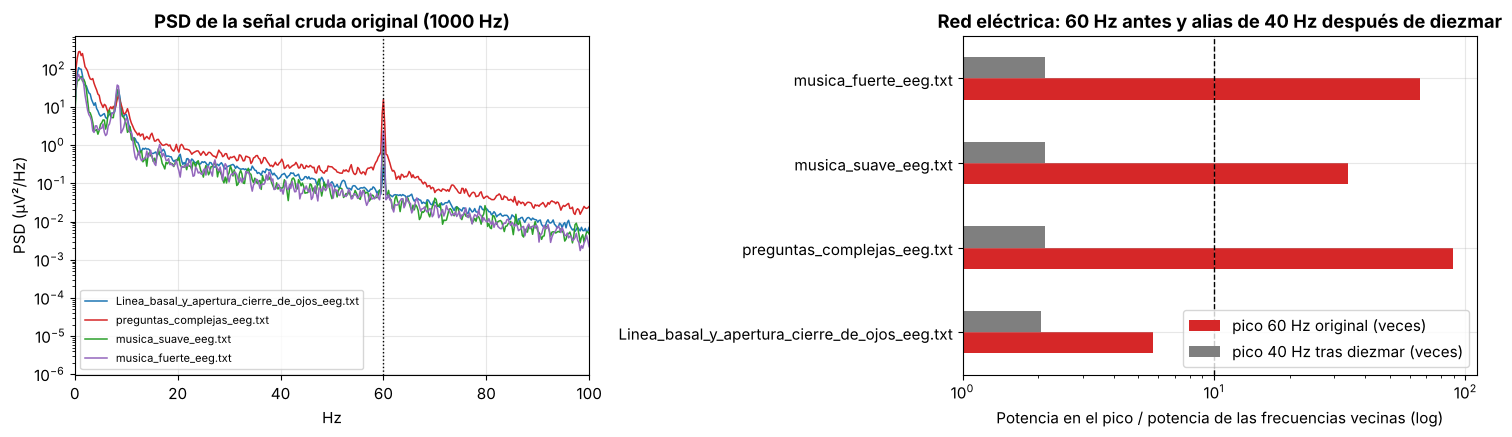

,pico 60 Hz original (veces),pico 40 Hz tras diezmar (veces)
Linea_basal_y_apertura_cierre_de_ojos_eeg.txt,4.7,1.1
preguntas_complejas_eeg.txt,88.0,1.1
musica_suave_eeg.txt,33.3,1.1
musica_fuerte_eeg.txt,64.8,1.1


,archivo,dispositivo,líneas angostas (Hz → % de la potencia)
0,Linea_basal_y_apertura_cierre_de_ojos_eeg.txt,2A:08,ninguna
1,preguntas_complejas_eeg.txt,2A:08,ninguna
2,musica_suave_eeg.txt,2A:08,8.35 Hz → 6.2 %
3,musica_fuerte_eeg.txt,2A:08,"2.1 Hz → 5.6 %, 8.4 Hz → 9.2 %"


In [6]:
def psd(x, fs=FS, nperseg=400):
    return signal.welch(x - np.mean(x), fs=fs, nperseg=min(nperseg, len(x)))

def pico_relativo(f, P, f0=40, ancho=2):
    vecinos = P[(np.abs(f - f0) > ancho) & (np.abs(f - f0) < 6)]
    return P[np.argmin(np.abs(f - f0))] / np.median(vecinos)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for _, fila in tabla_lectura.iterrows():
    r = senales[fila.archivo]
    # señal original a 1000 Hz: aquí la red aparece en su lugar real (60 Hz)
    fo, Po = signal.welch(r["eeg_uV_orig"] - np.mean(r["eeg_uV_orig"]), fs=r["fs_orig"], nperseg=4 * r["fs_orig"])
    r["pico60"] = pico_relativo(fo, Po, f0=60)
    ax[0].semilogy(fo, Po, color=COLOR.get(fila["condición"], "gray"), lw=1.1, label=fila.archivo)
    # señal diezmada a 100 Hz: comprobamos que no aparezca el alias en 40 Hz
    f, P = psd(r["eeg_uV"][~r["saturada"]] if r["saturada"].mean() < 0.5 else r["eeg_uV"])
    r["pico40"] = pico_relativo(f, P)
ax[0].axvline(60, color="k", ls=":", lw=1); ax[0].set_xlim(0, 100)
ax[0].set_xlabel("Hz"); ax[0].set_ylabel("PSD (µV²/Hz)"); ax[0].set_title("PSD de la señal cruda original (1000 Hz)")
ax[0].legend(fontsize=8)
picos = pd.DataFrame({"pico 60 Hz original (veces)": {a: senales[a]["pico60"] for a in tabla_lectura.archivo},
                      "pico 40 Hz tras diezmar (veces)": {a: senales[a]["pico40"] for a in tabla_lectura.archivo}})
picos.plot.barh(ax=ax[1], color=["tab:red", "tab:gray"], log=True)
ax[1].axvline(10, color="k", ls="--", lw=1)
ax[1].set_xlabel("Potencia en el pico / potencia de las frecuencias vecinas (log)")
ax[1].set_title("Red eléctrica: 60 Hz antes y alias de 40 Hz después de diezmar")
plt.tight_layout(); plt.show()
display(picos.round(1))

def lineas_angostas(x, fs=FS, prominencia_log=2.0, fraccion_min=0.04):
    # Picos espectrales muy angostos (interferencias): >100 veces sobre su entorno y >= 4 % de la potencia
    f, P = signal.welch(x - np.mean(x), fs=fs, nperseg=min(20 * fs, len(x)))
    total = P[(f >= 1) & (f <= 45)].sum()
    picos_idx, props = signal.find_peaks(np.log10(P), prominence=prominencia_log)
    lineas = []
    for p in picos_idx:
        fraccion = P[max(0, p - 2): p + 3].sum() / total
        if 1.5 <= f[p] <= 48 and fraccion >= fraccion_min:
            lineas.append((round(float(f[p]), 2), round(100 * fraccion, 1)))
    return lineas

i_rec = 4 * FS   # se ignoran los primeros 4 s (ver A.6)
filas = []
for a in tabla_lectura.archivo:
    r = senales[a]
    r["lineas_detectadas"] = lineas_angostas(r["eeg_uV"][i_rec:])
    filas.append({"archivo": a, "dispositivo": r["dispositivo"],
                  "líneas angostas (Hz → % de la potencia)": ", ".join(f"{fr} Hz → {pc} %" for fr, pc in r["lineas_detectadas"]) or "ninguna"})
display(pd.DataFrame(filas))

### ✍️ Pregunta A.3
1. ¿Qué archivos tienen un pico grande en 40 Hz? ¿Tienen algo en común (mira el **dispositivo**)?
2. Según la fórmula de aliasing, ¿de dónde viene ese pico? ¿Qué filtro *notch* deberíamos usar: 60 Hz o 40 Hz?
3. ¿Qué **otras líneas angostas** encontró el detector? ¿En qué dispositivo? ¿Caen dentro de alguna banda cerebral? ¿Qué pasaría con la potencia de esa banda si no las quitamos?

**Respuesta A.3**

1. Ningún archivo tiene pico en 40 Hz: después de diezmar, el pico en 40 Hz es de solo **1.1 veces** sus vecinos en los cuatro, o sea, nada. En cambio, en la señal original de 1000 Hz sí hay un pico claro en **60 Hz**: preguntas complejas **88 veces**, música fuerte 64.8, música suave 33.3 y basal 4.7. Todos son del mismo equipo (2A:08), así que la diferencia no es por el dispositivo. Puede deberse al contacto de los electrodos o a cosas cerca del participante en cada momento.
2. En nuestro caso **no hay aliasing**: como grabamos a 1000 Hz, los 60 Hz están por debajo de Nyquist (500 Hz) y aparecen en su lugar real. El alias en 40 Hz solo aparecería si muestreáramos directamente a 100 Hz. Si trabajáramos a 1000 Hz habría que usar un **notch en 60 Hz**. Como diezmamos con `decimate`, su filtro antialiasing ya quita los 60 Hz, así que no usamos notch (`NOTCH_HZ = None`). Un notch en 40 Hz no tendría nada que quitar.
3. El detector encontró **8.35 Hz** en música suave (6.2 % de la potencia) y **2.1 Hz** y **8.4 Hz** en música fuerte (5.6 % y 9.2 %). Caen en **alfa** (8.4 Hz) y **delta** (2.1 Hz). Pero no creemos que sean interferencias: la línea basal tiene su frecuencia pico en **8.5 Hz** y en la gráfica de bandas (B.3) se ve una alfa muy clara. Entonces esa "línea" de 8.4 Hz parece ser la **alfa del propio participante**, que en registros cortos (30 s) se ve muy angosta. Si la quitáramos con un notch, **borraríamos la alfa**: en la Pregunta 3b se ve que la alfa de música suave bajaría de 45.4 % a 30.4 %. Por eso pusimos `QUITAR_LINEAS = False`.

<a id="A5"></a>
## A.5 Control de calidad automático

Resumimos la calidad de cada archivo con un **semáforo**:

| Estado | Criterio |
|---|---|
| ✅ Bueno | Sin saturación, sin pico en 40 Hz (< 10 veces sus vecinos) y sin otras líneas angostas |
| ⚠️ Revisar | Saturación < 1 %, pico de 40 Hz ≥ 10 veces **o** líneas angostas (interferencias que un filtro puede quitar) |
| ❌ Problemático | Saturación ≥ 1 % de las muestras |

También calculamos la **curtosis** de la señal. Una curtosis alta indica **eventos aislados muy grandes** (parpadeos, movimientos, saltos), típicos de artefactos.

In [7]:
filas = []
for _, fila in tabla_lectura.iterrows():
    r = senales[fila.archivo]
    pct = 100 * r["sat_orig"].mean()
    otras = [fr for fr, _ in r["lineas_detectadas"] if abs(fr - 40) > 1]
    estado = "❌" if pct >= 1 else ("⚠️" if (pct > 0 or r["pico40"] >= 10 or otras) else "✅")
    x = r["eeg_uV"] - np.mean(r["eeg_uV"])
    filas.append({"archivo": fila.archivo, "condición": fila["condición"], "dispositivo": fila.dispositivo,
                  "% saturado": round(100 * r["sat_orig"].mean(), 2), "pico 60 Hz original": round(r["pico60"], 1),
                  "pico 40 Hz (veces)": round(r["pico40"], 1),
                  "otras líneas (Hz)": ", ".join(map(str, otras)) or "-",
                  "desv. estándar (µV)": round(np.std(x), 2), "curtosis": round(kurtosis(x), 1),
                  "estado": estado})
calidad = pd.DataFrame(filas)
display(calidad)

,archivo,condición,dispositivo,% saturado,pico 60 Hz original,pico 40 Hz (veces),otras líneas (Hz),desv. estándar (µV),curtosis,estado
0,Linea_basal_y_apertura_cierre_de_ojos_eeg.txt,basal,2A:08,6.38,4.7,1.1,-,15.52,0.8,❌
1,preguntas_complejas_eeg.txt,preguntas_complejas,2A:08,29.39,88.0,1.1,-,25.32,-1.0,❌
2,musica_suave_eeg.txt,musica_suave,2A:08,3.22,33.3,1.1,8.35,13.12,1.4,❌
3,musica_fuerte_eeg.txt,musica_fuerte,2A:08,2.54,64.8,1.1,"2.1, 8.4",13.27,1.0,❌


### ✍️ Pregunta A.4
1. ¿Qué archivos quedaron en ❌ y en ⚠️? ¿Por qué motivo cada uno?
2. ¿Qué archivo tiene la curtosis más alta? Relaciónalo con la columna *segundos con saturación* de A.2.

**Respuesta A.4**

1. Los cuatro archivos quedaron en ❌ porque todos tienen **saturación ≥ 1 %**: preguntas complejas 29.39 %, basal 6.38 %, música suave 3.22 % y música fuerte 2.54 %. Ninguno queda en ⚠️ ni en ✅. El peor por mucho es preguntas complejas.
2. La curtosis más alta es la de **música suave (1.4)**, pero en general todas son bajas (entre −1.0 y 1.4). Lo interesante es que **preguntas complejas tiene curtosis negativa (−1.0)**, aunque es el registro con más saturación. Como vimos en A.2, su saturación no son picos aislados, sino mesetas largas en los dos extremos (segundos 8, 10, 11, 12... casi seguidos). Eso hace que la distribución de valores sea "aplanada", con muchos valores en los bordes, y no "picuda". O sea, la curtosis sirve para detectar eventos aislados, pero no detecta una señal que satura todo el tiempo.

<a id="A6"></a>
## A.6 Conclusiones de la Parte A: decisiones para el procesamiento

La revisión de los datos nos lleva a **cuatro decisiones** que aplicaremos en la Parte B. Ajústalas si tus datos lo requieren:

| Parámetro | Valor por defecto | ¿Por qué? |
|---|---|---|
| `RECORTE_INICIO_S` | 4 s | Al iniciar la adquisición, el amplificador tarda unos segundos en estabilizarse |
| `NOTCH_HZ` | 40 Hz → **nosotros: `None`** | En la guía es el alias de 60 Hz. En nuestros datos el antialiasing de `decimate` ya quitó los 60 Hz y no hay pico en 40 Hz |
| `QUITAR_LINEAS` | `True` → **nosotros: `False`** | Las "líneas" que se detectaron en 8.4 Hz coinciden con la alfa del participante; si las quitamos, borramos la alfa (ver Pregunta 3b) |
| Rechazo de épocas | Toda época con al menos una muestra saturada | La saturación destruye información que ningún filtro puede recuperar |

### ✍️ Pregunta A.5
Escribe en 3 a 4 líneas tus conclusiones sobre la calidad de tus datos. ¿Hay algún archivo que no usarías? ¿Por qué podría ser un problema que se hayan usado **dos dispositivos distintos**?

**Respuesta A.5 — Conclusiones de la Parte A**

La calidad de nuestros datos no es muy buena, principalmente por la **saturación**. El registro de **preguntas complejas** satura el 29 % del tiempo y casi todo el registro está afectado: con la regla de rechazar las épocas saturadas, solo nos quedan **3 de 87 épocas**. Lo usaríamos con mucho cuidado o no lo usaríamos para sacar conclusiones. La basal y las músicas sí se pueden usar después de descartar las épocas saturadas.

La interferencia de 60 Hz sí existe, pero se elimina sola al diezmar a 100 Hz. Lo de los **dos dispositivos** no nos afecta, porque usamos uno solo. El problema de usar dos equipos es que cada uno deja su "huella" (ruido, ganancia, interferencias), y el modelo podría aprender el equipo en vez de la condición. En nuestro caso hay otras posibles confusiones: el **orden** de las grabaciones (las músicas fueron al final y casi seguidas) y que la basal mezcla ojos cerrados y ojos abiertos en un solo archivo, sin marcas de tiempo.

In [8]:
# =================== ✍️ DECISIONES (puedes modificarlas) ===================
RECORTE_INICIO_S = 4      # segundos que se descartan al inicio de cada registro
NOTCH_HZ = None           # el filtro antialiasing de decimate ya quitó los 60 Hz y no hay alias en 40 Hz (ver A.4)
QUITAR_LINEAS = False     # lo desactivamos: las "líneas" de 8.4 Hz que detectó A.4 son la alfa del participante (ver respuesta A.3)
# ==========================================================================
print(f"Recorte inicial: {RECORTE_INICIO_S} s | Notch: {NOTCH_HZ} Hz | Quitar líneas angostas: {QUITAR_LINEAS}")

Recorte inicial: 4 s | Notch: None Hz | Quitar líneas angostas: False


---
<a id="parteB"></a>
# 🅱️ PARTE B — Tratamiento y extracción de características *(≈ 40 min)*

[⬆️ Volver al índice](#indice)

<a id="B1"></a>
## B.1 El pipeline de procesamiento

Este es el camino que recorrerá cada registro, siguiendo el esquema de la clase:

| Paso | Etapa | Qué hace | Sección |
|---|---|---|---|
| 1 | **Filtrado** | Quita la deriva lenta, el ruido de alta frecuencia y la red eléctrica (40 Hz) | B.2 |
| 2 | **Análisis de ritmos** | Mide cuánta potencia hay en delta, theta, alfa, beta y gamma | B.3 |
| 3 | **Limpieza con ICA** | Separa y elimina componentes de artefactos (parpadeos, interferencia) | B.4 |
| 4 | **Preprocesamiento** | Normalización (z-score) y corte en épocas de 2 s; se rechazan las saturadas | B.5 |
| 5 | **Extracción de características** | ~22 números por época | B.6 |
| 6 | **Ingeniería de características** | Cocientes entre bandas, logaritmos, tabla final | B.6–B.7 |
| 7 | **Clasificación** | ¿Podemos reconocer la condición a partir de las características? | B.8 |

<a id="B2"></a>
## B.2 Filtrado

| Filtro | Configuración | ¿Por qué? |
|---|---|---|
| **Pasa-banda Butterworth** | 1 – 45 Hz, orden 4 | Quita la deriva lenta (< 1 Hz) y se queda por debajo de Nyquist (50 Hz). El ejemplo de MNE también recomienda un pasa-altos de 1 Hz antes de aplicar ICA |
| **Notch** | 40 Hz (Q = 20) | Elimina el **alias de la red eléctrica**. En nuestro caso no lo usamos (`NOTCH_HZ = None`): el antialiasing de `decimate` ya quitó los 60 Hz |
| **Notch angostos** | En cada línea detectada en A.4 (Q = 30, ~0.15–0.8 Hz de ancho) | Elimina las otras interferencias sin borrar la banda cerebral donde caen |

Se filtra "ida y vuelta" (`filtfilt`) para no desfasar la señal. Veamos el efecto en el archivo con **más saturación** (en nuestros datos ya no hay pico de red después de diezmar).

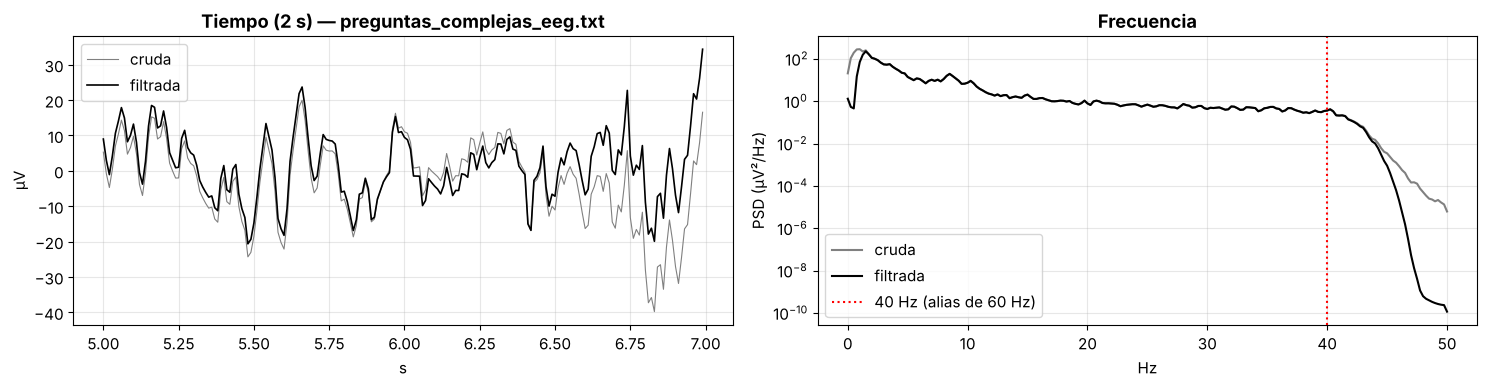

In [9]:
def filtrar_eeg(x, fs=FS, notch=NOTCH_HZ, lineas=()):
    sos = signal.butter(4, [1, 45], btype="bandpass", fs=fs, output="sos")
    y = signal.sosfiltfilt(sos, x - np.mean(x))
    if notch and notch < fs / 2:
        b, a = signal.iirnotch(notch, 20, fs=fs)
        y = signal.filtfilt(b, a, y)
    elif notch:
        print(f"⚠️ Notch de {notch} Hz imposible: está por encima de Nyquist ({fs/2:.0f} Hz). No se aplicó.")
    for f0 in lineas:                       # notch angosto en cada línea de interferencia
        if notch is None or abs(f0 - notch) > 1:
            b, a = signal.iirnotch(f0, 30, fs=fs)
            y = signal.filtfilt(b, a, y)
    return y

def lineas_de(archivo, quitar=QUITAR_LINEAS):
    return [fr for fr, _ in senales[archivo]["lineas_detectadas"]] if quitar else []

i0 = int(RECORTE_INICIO_S * FS)
peor = max(senales, key=lambda a: senales[a]["sat_orig"].mean())   # el registro con más saturación
x_crudo = senales[peor]["eeg_uV"][i0:] - np.mean(senales[peor]["eeg_uV"][i0:])
x_filt = filtrar_eeg(senales[peor]["eeg_uV"][i0:], lineas=lineas_de(peor))
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
t = np.arange(len(x_crudo)) / FS
sl = (t >= 5) & (t < 7)
ax[0].plot(t[sl], x_crudo[sl], color="gray", lw=0.8, label="cruda")
ax[0].plot(t[sl], x_filt[sl], color="black", lw=1.2, label="filtrada")
ax[0].set_title(f"Tiempo (2 s) — {peor}"); ax[0].set_xlabel("s"); ax[0].set_ylabel("µV"); ax[0].legend()
for s, nom, col in [(x_crudo, "cruda", "gray"), (x_filt, "filtrada", "black")]:
    f, P = psd(s); ax[1].semilogy(f, P, color=col, label=nom)
ax[1].axvline(40, color="r", ls=":", label="40 Hz (alias de 60 Hz)")
ax[1].set_xlabel("Hz"); ax[1].set_ylabel("PSD (µV²/Hz)"); ax[1].set_title("Frecuencia"); ax[1].legend()
plt.tight_layout(); plt.show()

### 🔎 Observa
- **En la frecuencia:** la potencia por debajo de 1 Hz cae mucho (se quita la deriva lenta) y por encima de 45 Hz también. Entre 1 y 45 Hz las curvas casi coinciden.
- **En el tiempo:** la filtrada queda centrada en cero y sin las subidas lentas de la cruda.

<a id="B3"></a>
## B.3 Ritmos cerebrales: delta, theta, alfa, beta y gamma

### 📖 Dos formas de "ver" las bandas
1. **En el tiempo:** filtramos la señal en cada banda y vemos cómo oscila cada "sección de la orquesta".
2. **En la frecuencia:** integramos la PSD de Welch dentro de cada banda para obtener la **potencia de banda**:
   - **Absoluta** (µV²): cuánta energía hay en la banda.
   - **Relativa** (%): qué fracción del total (1–45 Hz) corresponde a esa banda. Es más fácil de comparar entre registros y dispositivos.

> ⚠️ **Gamma en estos datos:** con Fs = 100 Hz solo vemos gamma entre 30 y 45 Hz, y el notch quita 38–42 Hz. La gamma de superficie, además, suele estar dominada por **actividad muscular**. Hay que interpretarla con mucha cautela.

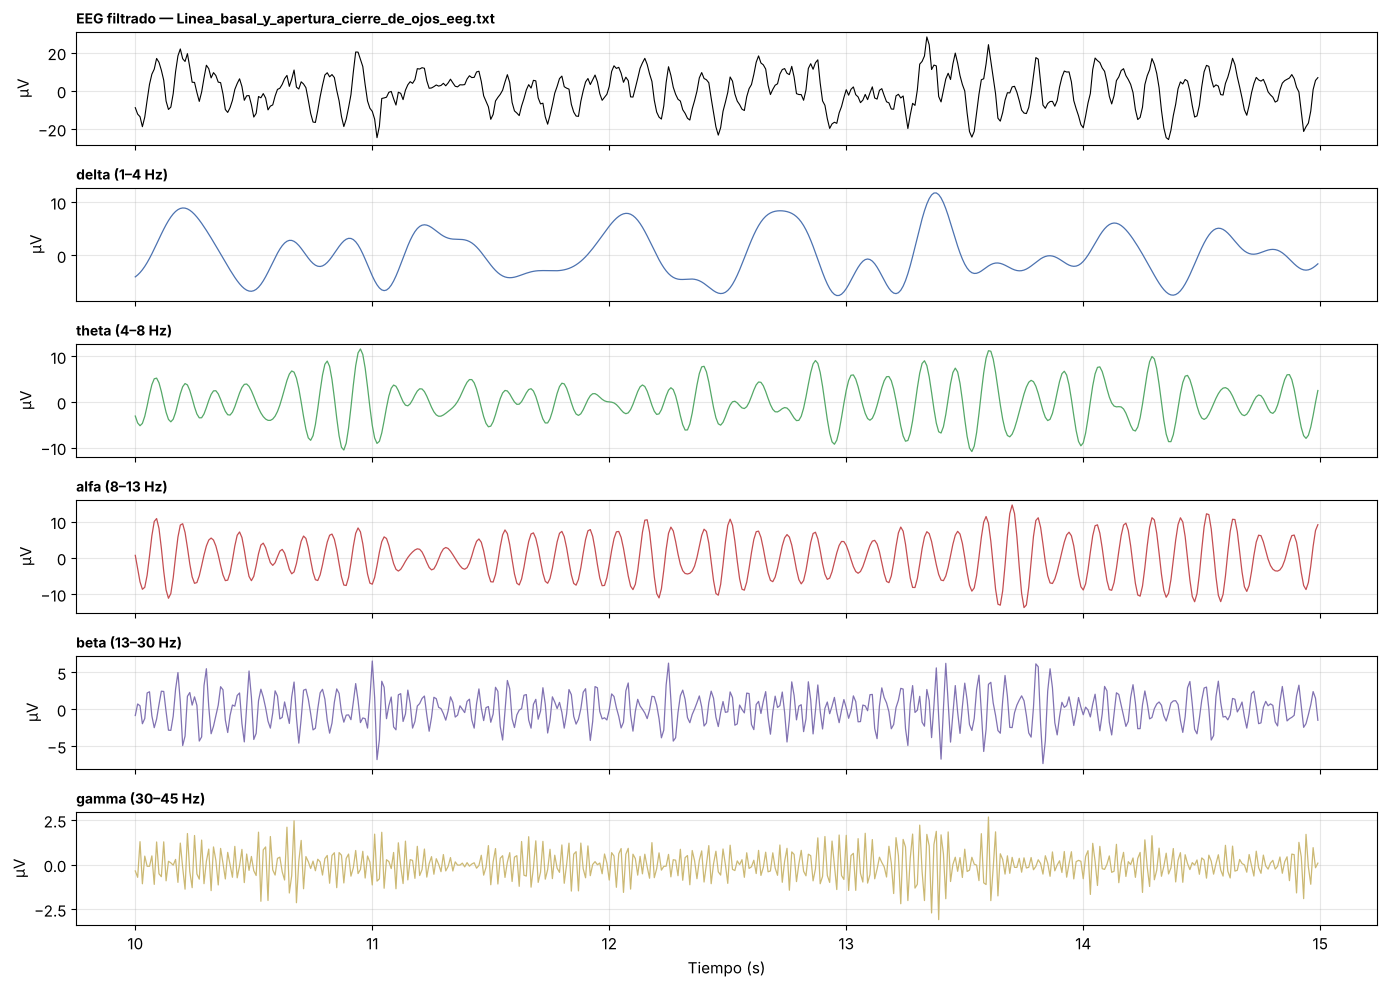

In [10]:
for a, r in senales.items():
    r["filtrada"] = filtrar_eeg(r["eeg_uV"][i0:], lineas=lineas_de(a))
    r["sat_rec"] = r["saturada"][i0:]

# 1) Bandas en el tiempo para el registro basal más limpio
basales = [a for a in calidad[calidad["condición"] == "basal"].sort_values("pico 40 Hz (veces)").archivo]
ref = basales[0] if basales else list(senales)[0]
x = senales[ref]["filtrada"]; t = np.arange(len(x)) / FS; sl = (t >= 10) & (t < 15)
fig, ax = plt.subplots(6, 1, figsize=(14, 10), sharex=True)
ax[0].plot(t[sl], x[sl], color="black", lw=0.8); ax[0].set_title(f"EEG filtrado — {ref}", loc="left", fontsize=10)
for a, (b, (lo, hi)) in zip(ax[1:], BANDAS.items()):
    sos = signal.butter(4, [lo, hi], btype="bandpass", fs=FS, output="sos")
    a.plot(t[sl], signal.sosfiltfilt(sos, x)[sl], color=COLOR_BANDA[b], lw=0.9)
    a.set_title(f"{b} ({lo}–{hi} Hz)", loc="left", fontsize=10)
for a in ax: a.set_ylabel("µV")
ax[-1].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

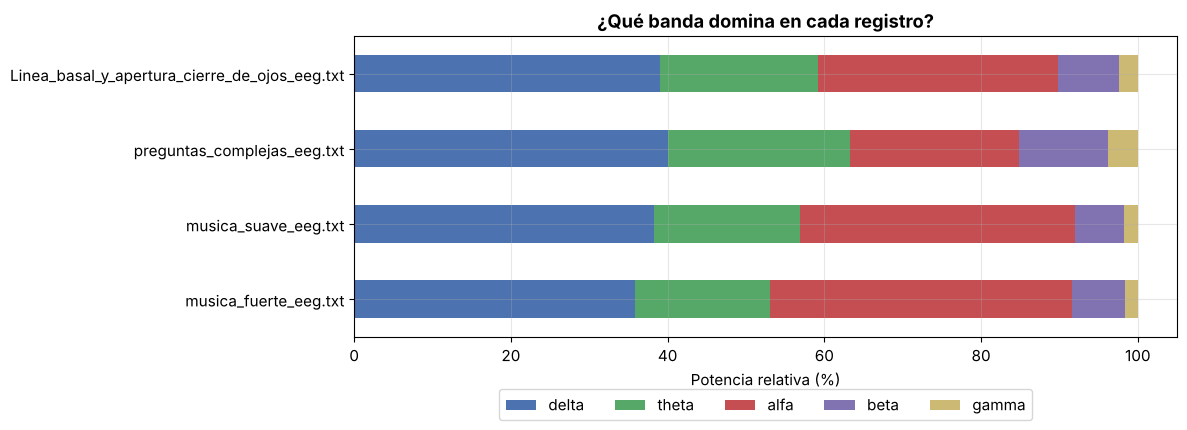

,delta,theta,alfa,beta,gamma
Linea_basal_y_apertura_cierre_de_ojos_eeg.txt,39.1,20.1,30.6,7.8,2.5
preguntas_complejas_eeg.txt,40.1,23.1,21.5,11.5,3.7
musica_suave_eeg.txt,38.3,18.6,35.2,6.2,1.7
musica_fuerte_eeg.txt,35.8,17.3,38.5,6.8,1.6


In [11]:
# 2) Potencia relativa por banda en cada registro (PSD de Welch sobre la señal filtrada, sin muestras saturadas)
def potencia_bandas(x, fs=FS):
    f, P = signal.welch(x - np.mean(x), fs=fs, nperseg=min(400, len(x)))
    total = P[(f >= 1) & (f <= 45)].sum()
    return {b: P[(f >= lo) & (f < hi)].sum() / total for b, (lo, hi) in BANDAS.items()}

pot = pd.DataFrame({a: potencia_bandas(r["filtrada"][~r["sat_rec"]]) for a, r in senales.items()}).T * 100
pot = pot.loc[tabla_lectura.archivo]
ax = pot.plot.barh(stacked=True, figsize=(12, 4.5), color=[COLOR_BANDA[b] for b in BANDAS])
ax.set_xlabel("Potencia relativa (%)"); ax.set_title("¿Qué banda domina en cada registro?"); ax.invert_yaxis()
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15)); plt.tight_layout(); plt.show()
display(pot.round(1))

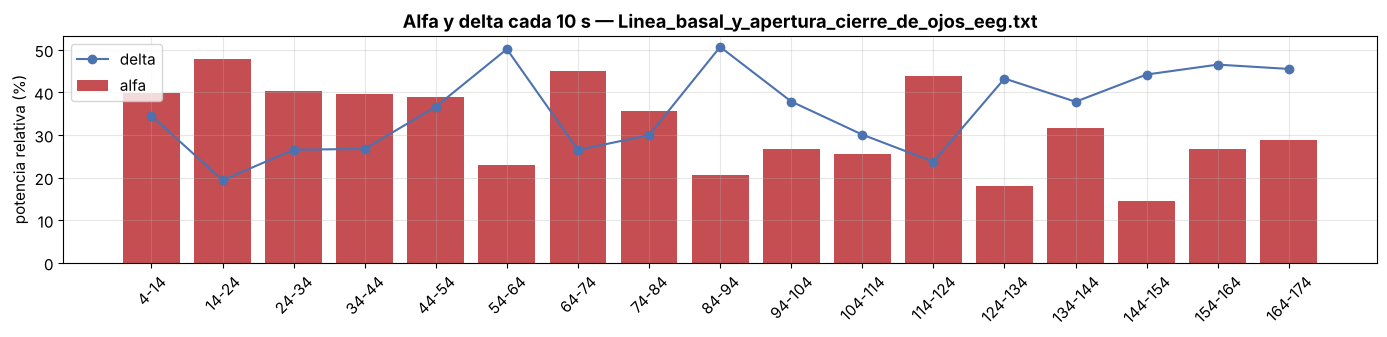

,ventana (s),alfa (%),delta (%),% saturado
0,4-14,39.9,34.5,4.5
1,14-24,47.8,19.4,0.0
2,24-34,40.3,26.5,4.5
3,34-44,39.7,26.7,0.0
4,44-54,39.0,36.6,0.5
5,54-64,23.0,50.1,5.2
6,64-74,45.0,26.5,1.0
7,74-84,35.6,30.0,0.0
8,84-94,20.6,50.7,14.6
9,94-104,26.8,37.8,18.8


In [12]:
# Extra (grupo 11): no tenemos un archivo aparte de "ojos abiertos". Nuestro registro basal incluye la parte de
# ojos cerrados y la de apertura/cierre de ojos, así que miramos cómo cambia la alfa cada 10 s dentro del mismo archivo
x = senales[ref]["filtrada"]; sat = senales[ref]["sat_rec"]; w = 10 * FS
filas = []
for k in range(len(x) // w):
    seg = x[k*w:(k+1)*w][~sat[k*w:(k+1)*w]]
    pb = potencia_bandas(seg)
    filas.append({"ventana (s)": f"{RECORTE_INICIO_S + 10*k}-{RECORTE_INICIO_S + 10*(k+1)}", "alfa (%)": 100 * pb["alfa"],
                  "delta (%)": 100 * pb["delta"], "% saturado": 100 * sat[k*w:(k+1)*w].mean()})
alfa_t = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(alfa_t["ventana (s)"], alfa_t["alfa (%)"], color=COLOR_BANDA["alfa"], label="alfa")
ax.plot(alfa_t["ventana (s)"], alfa_t["delta (%)"], "o-", color=COLOR_BANDA["delta"], label="delta")
ax.set_ylabel("potencia relativa (%)"); ax.set_title(f"Alfa y delta cada 10 s — {ref}"); ax.legend()
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
display(alfa_t.round(1))

### ✍️ Pregunta B.1
1. ¿Qué banda domina en los registros **basales** (ojos cerrados)? ¿Es la alfa, como se esperaría?
2. Compara `Basal1` con `ojos_abiertos`. ¿Disminuye la alfa al abrir los ojos? ¿Qué banda cambia más?
3. *(Para pensar)* Los electrodos están en **Fp1/Fp2** (frente). La alfa de reposo es más fuerte en la zona **occipital** (nuca). ¿Cómo influye esto en lo que ves?

**Respuesta B.1**

1. En nuestra basal **sí se ve la alfa**. Con la señal completa (sin muestras saturadas), la delta tiene 39.1 % y la alfa 30.6 %. Pero en el promedio por épocas (B.7) la alfa es la que domina, con **41 %**, y la frecuencia pico es **8.5 Hz**. En la gráfica de bandas en el tiempo se ve una oscilación alfa clara y continua. También en las músicas domina la alfa (35.2 % y 38.5 %), lo que tiene sentido si se escucharon con los ojos cerrados.
2. No tenemos un archivo separado de ojos abiertos, pero nuestro registro basal tiene la parte de apertura/cierre de ojos al final. En la celda extra que agregamos (alfa cada 10 s) se ve que **en los primeros ~84 s la alfa está casi siempre entre 36 % y 48 %**, y **desde el segundo ~84 baja**, con varias ventanas entre 14 % y 27 %. Al mismo tiempo sube la delta (hasta ~50 %) y aparece más saturación (hasta 23 %). Esto es compatible con el **bloqueo alfa** al abrir los ojos y con los movimientos oculares, que se ven como delta en un electrodo frontal. No lo podemos afirmar del todo porque no marcamos en qué segundo se abrían y cerraban los ojos.
3. *(Conceptual)* La alfa de reposo es más fuerte en la zona **occipital**, y con electrodos en Fp1 y Fp2 estamos lejos de ahí. Además, al restar dos puntos casi simétricos se atenúa lo que es común a ambos. Aun así, en nuestros datos la alfa se ve bastante. Puede ser que llegue por conducción de volumen o que la referencia en O2 influya, pero no lo podemos comprobar con un solo canal. La zona frontal también es muy sensible a los ojos y a los músculos de la frente, y eso se nota en la delta y la saturación.

<a id="B4"></a>
## B.4 Filtro ICA: separar el cerebro de los artefactos

### B.4.1 📖 Definición fácil: el problema de la fiesta (*cocktail party*)
Imagina una fiesta con **3 personas hablando** y **3 micrófonos** en distintos lugares. Cada micrófono graba una **mezcla** de las tres voces. El **Análisis de Componentes Independientes (ICA)** es un algoritmo que, solo con las grabaciones de los micrófonos, **recupera cada voz por separado**.

En el EEG:
- Los **micrófonos** son los electrodos.
- Las **voces** son las fuentes: actividad cerebral, parpadeos, músculos, red eléctrica.

Si separamos las fuentes, podemos **apagar las de artefactos** y reconstruir una señal limpia.

### En términos matemáticos

$$
\underbrace{\mathbf{X}}_{\text{electrodos}} = \underbrace{\mathbf{A}}_{\text{mezcla}} \cdot \underbrace{\mathbf{S}}_{\text{fuentes}}
\qquad\Longrightarrow\qquad
\hat{\mathbf{S}} = \mathbf{W}\,\mathbf{X}, \quad \mathbf{W} \approx \mathbf{A}^{-1}
$$

ICA estima la matriz de "desmezcla" **W** suponiendo que:
1. Las fuentes son **estadísticamente independientes**.
2. Las fuentes **no son gaussianas**. El algoritmo FastICA busca justamente las direcciones más "no gaussianas".
3. Hay **al menos tantos canales como fuentes** que queremos separar.

**Limpieza en 3 pasos:** (1) descomponer en componentes; (2) **identificar** las de artefactos; (3) ponerlas en cero y **reconstruir**.

### B.4.2 Demostración con señales simuladas
Antes de usar datos reales, probamos ICA en un caso donde **conocemos la respuesta**: 3 fuentes (alfa de 10 Hz, parpadeos y ráfagas musculares) mezcladas en 3 "electrodos".

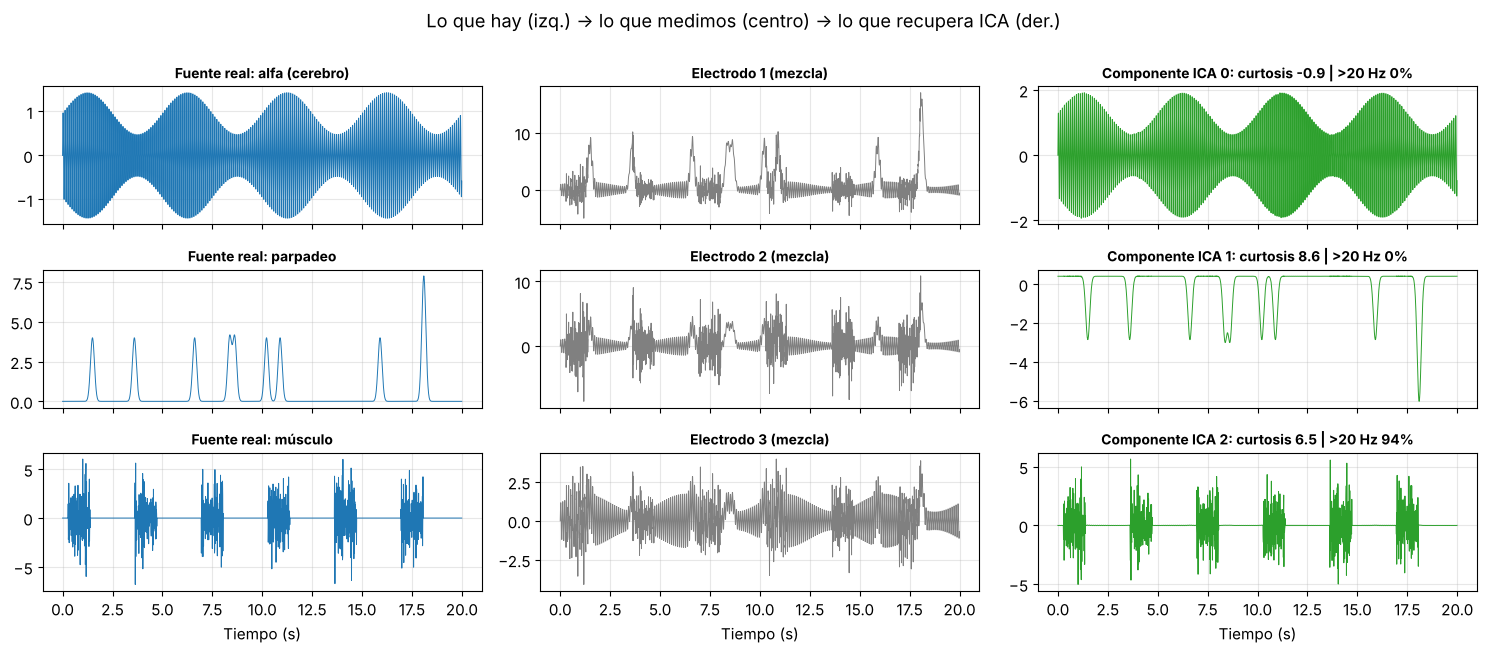

In [13]:
rng = np.random.default_rng(1)
ts = np.arange(0, 20, 1/FS)
alfa = np.sin(2*np.pi*10*ts) * (1 + 0.5*np.sin(2*np.pi*0.2*ts))                 # fuente cerebral
parpadeo = sum(np.exp(-((ts - tp)**2) / (2*0.1**2)) for tp in rng.uniform(1, 19, 10)) * 4  # fuente ocular
b, a_ = signal.butter(4, [20, 45], "bandpass", fs=FS)
musculo = (np.sin(2*np.pi*0.3*ts) > 0.5) * signal.lfilter(b, a_, rng.standard_normal(len(ts))) * 3  # fuente muscular
S_real = np.c_[alfa, parpadeo, musculo]
A_mezcla = np.array([[1.0, 2.0, 0.6],     # electrodo 1 (frontal: mucho parpadeo)
                     [1.0, 0.8, 1.2],     # electrodo 2
                     [1.2, 0.3, 0.4]])    # electrodo 3
X = S_real @ A_mezcla.T

ica_demo = FastICA(n_components=3, whiten="unit-variance", random_state=0)
S_est = ica_demo.fit_transform(X)

def metricas_componente(s, fs=FS):
    f, P = signal.welch(s, fs=fs, nperseg=min(256, len(s)))
    tot = P[f >= 1].sum()
    return {"curtosis": kurtosis(s), "fracción > 20 Hz": P[f >= 20].sum() / tot,
            "fracción 38–42 Hz": P[(f >= 38) & (f <= 42)].sum() / tot}

fig, ax = plt.subplots(3, 3, figsize=(15, 6.5), sharex=True)
nombres = ["alfa (cerebro)", "parpadeo", "músculo"]
for k in range(3):
    ax[k, 0].plot(ts, S_real[:, k], lw=0.7); ax[k, 0].set_title(f"Fuente real: {nombres[k]}", fontsize=10)
    ax[k, 1].plot(ts, X[:, k], lw=0.7, color="gray"); ax[k, 1].set_title(f"Electrodo {k+1} (mezcla)", fontsize=10)
    m = metricas_componente(S_est[:, k])
    ax[k, 2].plot(ts, S_est[:, k], lw=0.7, color="tab:green")
    ax[k, 2].set_title(f"Componente ICA {k}: curtosis {m['curtosis']:.1f} | >20 Hz {m['fracción > 20 Hz']:.0%}", fontsize=10)
for a in ax[-1]: a.set_xlabel("Tiempo (s)")
plt.suptitle("Lo que hay (izq.) → lo que medimos (centro) → lo que recupera ICA (der.)", y=1.0)
plt.tight_layout(); plt.show()

### 🔎 Observa
- ICA recupera las tres fuentes a partir de las mezclas. El **orden** y el **signo** pueden cambiar: ICA no sabe cuál es cuál.
- Para **identificar** cada componente usamos dos métricas sencillas:
  - **Curtosis alta** → eventos aislados y grandes, como **parpadeos** o movimientos.
  - **Mucha potencia por encima de 20 Hz** → actividad **muscular**.

### B.4.3 ¿Cómo se hace en EEG multicanal? El ejemplo de MNE
El ejemplo [*Removing muscle ICA components*](https://mne.tools/stable/auto_examples/preprocessing/muscle_ica.html) de **MNE-Python** aplica ICA a un EEG de 59 canales:
1. Aplica un **pasa-altos de 1 Hz** ("ICA funciona mejor con un pasa-altos").
2. Ajusta un ICA de **15 componentes**.
3. Marca como **musculares** las componentes que cumplen los criterios de Dharmaprani et al. (2016):
   - **pendiente positiva** del espectro en escala log-log entre 7 y 75 Hz;
   - foco **periférico** en el mapa topográfico (lejos del vértex);
   - **un solo foco**, poco "suave" espacialmente;
   - y, además, una serie temporal "peluda", con picos como de EMG.
4. Compara la selección manual con la automática `ica.find_bads_muscle(raw)`.

```python
# Esquema del ejemplo de MNE (EEG multicanal; no se ejecuta en este cuaderno)
import mne
raw.filter(l_freq=1.0, h_freq=None)
ica = mne.preprocessing.ICA(n_components=15, method="picard", max_iter="auto", rng=97)
ica.fit(raw)
muscle_idx_auto, scores = ica.find_bads_muscle(raw)
ica.apply(raw, exclude=muscle_idx_auto)
```

> ⚠️ **Nuestro problema:** BITalino nos da **un solo canal**, e ICA necesita **al menos tantos canales como fuentes**. Además, sin varios electrodos no hay mapa topográfico, así que solo podemos usar los criterios **temporales y espectrales**.

### B.4.4 Solución para un canal: Wavelet-ICA
Una técnica usada en la literatura (Castellanos y Makarov, 2006) consiste en **fabricar "canales virtuales"** a partir del único canal:

1. Se descompone la señal con la **transformada wavelet** en **6 sub-bandas**. Es un análisis multirresolución: las sub-bandas **sumadas devuelven exactamente la señal original**.
2. Esas 6 sub-bandas se tratan como si fueran **6 electrodos**, y se aplica **FastICA**.
3. Se revisa cada componente:
   - **Más del 40 % de su potencia en 38–42 Hz** → es **interferencia de red** (alias). Se **elimina entera**. Solo aparece si no se usó el notch.
   - **Curtosis > 6** → contiene **transitorios** (parpadeos bruscos, movimientos, saltos). Se **corrige**: con una transformada wavelet se anulan solo los coeficientes **atípicamente grandes** (más de 4 desviaciones robustas). Es la idea del método WICA.
   - El resto se **conserva**.
4. Se vuelve a las sub-bandas y se **suman** para obtener la señal limpia.

> 💡 **¿Por qué corregir y no borrar?** En el EEG multicanal de MNE, una componente muscular es casi "pura" y se borra entera. Con un solo canal, cada componente mezcla un poco de cerebro y un poco de artefacto: si la borráramos entera, nos llevaríamos también una banda completa del EEG. Por eso solo "recortamos" la parte anómala.

Con Fs = 100 Hz y 6 niveles, las sub-bandas son aproximadamente:

| Sub-banda | Rango | Ritmo cercano |
|---|---|---|
| D1 | 25 – 50 Hz | gamma / beta alta |
| D2 | 12.5 – 25 Hz | beta |
| D3 | 6.25 – 12.5 Hz | alfa / theta alta |
| D4 | 3.1 – 6.25 Hz | theta |
| D5 | 1.6 – 3.1 Hz | delta |
| A5 | 0 – 1.6 Hz | muy lento (parpadeos, deriva) |

In [14]:
KURT_UMBRAL = 6       # curtosis por encima de la cual una componente contiene transitorios (artefactos)
LINEA_UMBRAL = 0.4    # fracción de potencia en 38–42 Hz por encima de la cual es interferencia de red
K_UMBRAL = 4          # umbral para "recortar" transitorios: coeficientes > K · desviación robusta
NOMBRES_SUBBANDA = ["D1 (25–50 Hz)", "D2 (12.5–25)", "D3 (6.25–12.5)", "D4 (3.1–6.25)", "D5 (1.6–3.1)", "A5 (0–1.6)"]

def subbandas_wavelet(x, nivel=5, wavelet="sym4"):
    # Análisis multirresolución (SWT): devuelve sub-bandas que SUMADAS reconstruyen x exactamente
    n = len(x); m = int(np.ceil(n / 2**nivel) * 2**nivel)
    xp = np.pad(x, (0, m - n), mode="reflect")
    comp = np.array(pywt.mra(xp, wavelet, level=nivel, transform="swt"))[:, :n]
    return comp[::-1]      # orden: D1 (rápida) ... A5 (lenta)

def quitar_transitorios(s, k=K_UMBRAL, wavelet="db4", nivel=4):
    # Corrección tipo WICA: en cada nivel wavelet se anulan SOLO los coeficientes atípicamente grandes
    coef = pywt.wavedec(s, wavelet, level=nivel)
    coef = [c * (np.abs(c) <= k * np.median(np.abs(c)) / 0.6745) for c in coef]
    return pywt.waverec(coef, wavelet)[:len(s)]

def ica_un_canal(x, kurt_umbral=KURT_UMBRAL, linea_umbral=LINEA_UMBRAL):
    V = subbandas_wavelet(x)                                     # (6, n): "canales virtuales"
    ica = FastICA(n_components=V.shape[0], whiten="unit-variance", random_state=0, max_iter=3000)
    S = ica.fit_transform(V.T)                                   # (n, 6): componentes independientes
    metr = pd.DataFrame([metricas_componente(S[:, k]) for k in range(S.shape[1])])
    aporte = [np.var(np.outer(S[:, k], ica.mixing_[:, k]).sum(axis=1)) / np.var(x) for k in range(S.shape[1])]
    metr["% varianza de la señal"] = 100 * np.array(aporte)
    metr["sub-banda dominante"] = [NOMBRES_SUBBANDA[j] for j in np.argmax(ica.mixing_**2, axis=0)]
    es_red = metr["fracción 38–42 Hz"] > linea_umbral
    es_trans = (metr["curtosis"] > kurt_umbral) & ~es_red
    metr["acción"] = np.where(es_red, "eliminar (red)", np.where(es_trans, "corregir (transitorios)", "conservar"))
    metr["artefacto"] = es_red | es_trans
    S_limpio = S.copy()
    for k in range(S.shape[1]):
        if es_red[k]:
            S_limpio[:, k] = 0                                   # componente de red: se elimina entera
        elif es_trans[k]:
            S_limpio[:, k] = quitar_transitorios(S[:, k])        # componente con transitorios: se corrige
    # Artefacto estimado = lo que se quitó, devuelto a sub-bandas y sumado
    artefacto = (ica.inverse_transform(S) - ica.inverse_transform(S_limpio)).sum(axis=1)
    sos = signal.butter(4, [1, 45], btype="bandpass", fs=FS, output="sos")
    x_limpia = x - signal.sosfiltfilt(sos, artefacto)            # se resta solo dentro de la banda 1–45 Hz
    return x_limpia, {"V": V, "S": S, "S_limpio": S_limpio, "metricas": metr}
print("✅ Funciones de Wavelet-ICA listas.")

✅ Funciones de Wavelet-ICA listas.


### B.4.5 Wavelet-ICA paso a paso sobre el registro con artefactos
La guía lo aplica al registro de parpadeo y masticación. Nosotros no tenemos ese registro, así que lo aplicamos al registro con **más saturación y artefactos**: **preguntas complejas**.

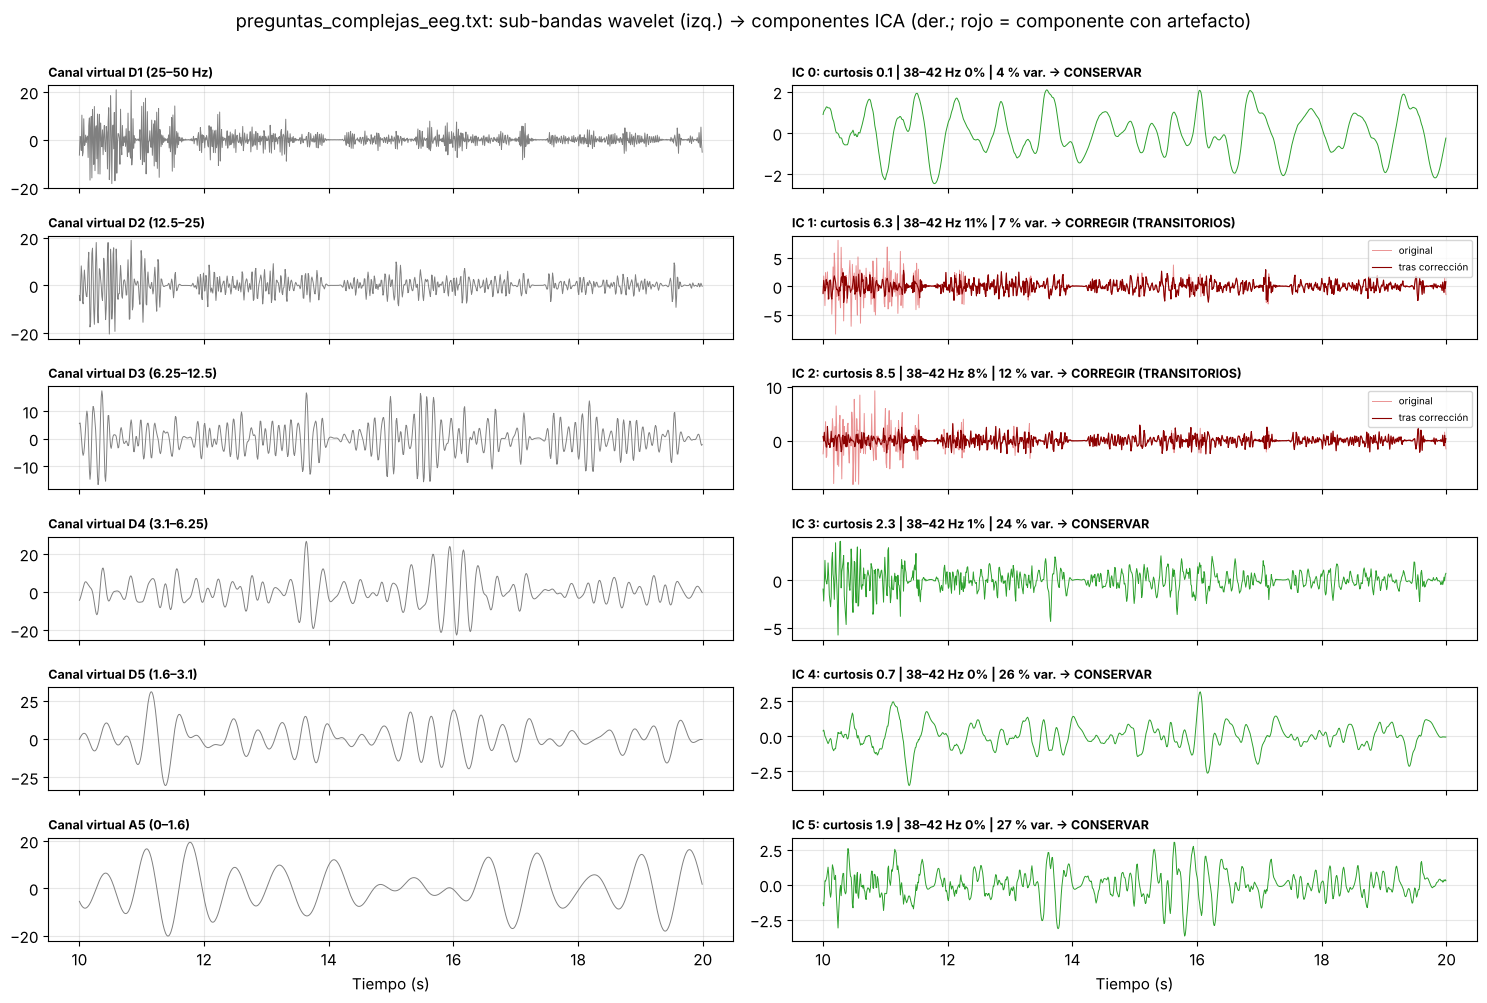

,curtosis,fracción > 20 Hz,fracción 38–42 Hz,% varianza de la señal,sub-banda dominante,acción,artefacto
0,0.069,0.000,0.000,3.874,A5 (0–1.6),conservar,False
1,6.303,0.467,0.109,7.343,D3 (6.25–12.5),corregir (transitorios),True
2,8.454,0.660,0.081,12.363,D2 (12.5–25),corregir (transitorios),True
3,2.333,0.081,0.010,23.983,D3 (6.25–12.5),conservar,False
4,0.669,0.000,0.000,25.731,D5 (1.6–3.1),conservar,False
5,1.872,0.005,0.000,26.706,D5 (1.6–3.1),conservar,False


In [15]:
cand = [a for a in senales if condicion_desde_nombre(a) == "preguntas_complejas"]
ej = cand[0] if cand else list(senales)[0]
x = senales[ej]["filtrada"]
x_limpia, det = ica_un_canal(x)
t = np.arange(len(x)) / FS; sl = (t >= 10) & (t < 20)

fig, ax = plt.subplots(6, 2, figsize=(15, 10), sharex=True)
for k in range(6):
    ax[k, 0].plot(t[sl], det["V"][k][sl], color="gray", lw=0.7)
    ax[k, 0].set_title(f"Canal virtual {NOMBRES_SUBBANDA[k]}", loc="left", fontsize=9)
    m = det["metricas"].iloc[k]
    if m["artefacto"]:
        ax[k, 1].plot(t[sl], det["S"][sl, k], color="tab:red", lw=0.7, alpha=0.5, label="original")
        ax[k, 1].plot(t[sl], det["S_limpio"][sl, k], color="darkred", lw=0.8, label="tras corrección")
        ax[k, 1].legend(loc="upper right", fontsize=7)
    else:
        ax[k, 1].plot(t[sl], det["S"][sl, k], color="tab:green", lw=0.7)
    ax[k, 1].set_title(f"IC {k}: curtosis {m['curtosis']:.1f} | 38–42 Hz {m['fracción 38–42 Hz']:.0%} | "
                       f"{m['% varianza de la señal']:.0f} % var. → {m['acción'].upper()}", loc="left", fontsize=9)
ax[-1, 0].set_xlabel("Tiempo (s)"); ax[-1, 1].set_xlabel("Tiempo (s)")
plt.suptitle(f"{ej}: sub-bandas wavelet (izq.) → componentes ICA (der.; rojo = componente con artefacto)", y=1.0)
plt.tight_layout(); plt.show()
display(det["metricas"].round(3))

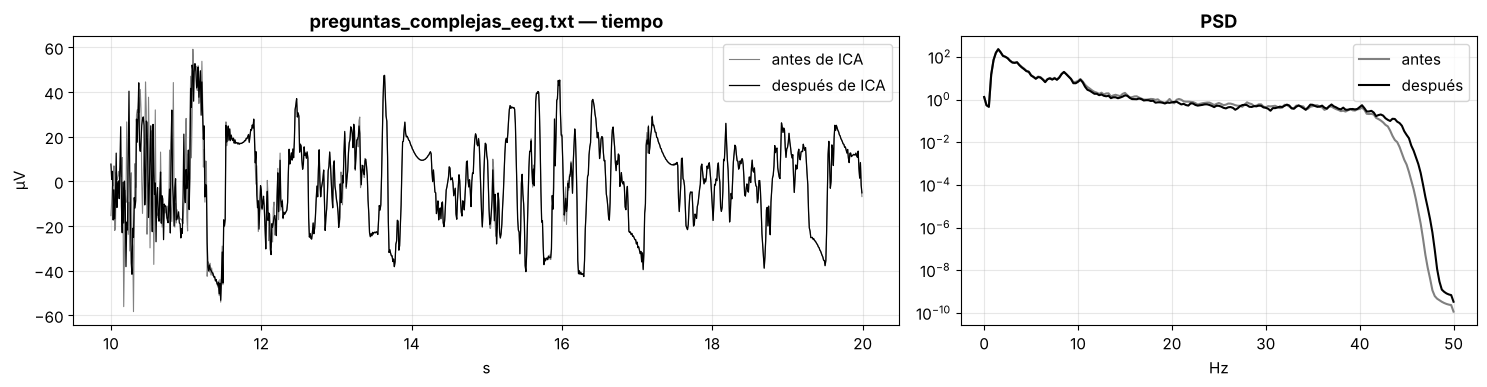

Varianza eliminada por ICA: 2.2 %


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].plot(t[sl], x[sl], color="gray", lw=0.8, label="antes de ICA")
ax[0].plot(t[sl], x_limpia[sl], color="black", lw=0.9, label="después de ICA")
ax[0].set_title(f"{ej} — tiempo"); ax[0].set_xlabel("s"); ax[0].set_ylabel("µV"); ax[0].legend()
for s, nom, col in [(x, "antes", "gray"), (x_limpia, "después", "black")]:
    f, P = psd(s); ax[1].semilogy(f, P, color=col, label=nom)
ax[1].set_title("PSD"); ax[1].set_xlabel("Hz"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Varianza eliminada por ICA: {100 * (1 - np.var(x_limpia) / np.var(x)):.1f} %")

### B.4.6 Aplicamos ICA a todos los registros

In [17]:
filas = []
for a, r in senales.items():
    r["limpia"], d = ica_un_canal(r["filtrada"])
    malos = d["metricas"].index[d["metricas"]["artefacto"]].tolist()
    filas.append({"archivo": a, "condición": condicion_desde_nombre(a), "ICs tratadas": malos,
                  "acción": [d["metricas"].loc[k, "acción"] for k in malos],
                  "curtosis de las tratadas": [round(v, 1) for v in d["metricas"].loc[malos, "curtosis"]],
                  "% varianza eliminada": round(max(0.0, 100 * (1 - np.var(r["limpia"]) / np.var(r["filtrada"]))), 1)})
resumen_ica = pd.DataFrame(filas).set_index("archivo").loc[tabla_lectura.archivo]
display(resumen_ica)

,condición,ICs tratadas,acción,curtosis de las tratadas,% varianza eliminada
archivo,,,,,
Linea_basal_y_apertura_cierre_de_ojos_eeg.txt,basal,[],[],[],0.0
preguntas_complejas_eeg.txt,preguntas_complejas,"[1, 2]","[corregir (transitorios), corregir (transitori...","[6.3, 8.5]",2.2
musica_suave_eeg.txt,musica_suave,[],[],[],0.0
musica_fuerte_eeg.txt,musica_fuerte,[],[],[],0.0


### ✍️ Pregunta B.2
1. En `parpadeo_masticacion`, ¿qué componente se trató como artefacto y por qué criterio? ¿Qué sub-banda domina en ella? ¿Qué tipo de evento muestra la gráfica en esa componente?
2. Mira el espectro antes y después: ¿bajó mucho la potencia en **delta** (parpadeos) y por encima de 20 Hz (masticación)? ¿Por qué un parpadeo **continuo y rítmico** es difícil de separar del EEG con un solo canal?
3. En los registros basales, ¿el ICA modificó mucho o poco la señal? ¿Es lo esperado?

**Respuesta B.2**

1. No tenemos registro de parpadeo y masticación, así que usamos **preguntas complejas**. Se trataron **dos componentes**, la IC 1 y la IC 2, porque su **curtosis (6.3 y 8.5) supera el umbral de 6**, o sea, tienen transitorios. La IC 1 tiene como sub-banda dominante **D3 (6.25–12.5 Hz)** y la IC 2 **D2 (12.5–25 Hz)**; aportan el 7 % y el 12 % de la varianza. En la gráfica se ven como una oscilación rápida con **ráfagas grandes al inicio** (entre los 10 y 11.5 s), que coinciden con una parte muy "peluda" de la señal. La corrección recortó solo esas ráfagas.
2. **Casi no bajó nada**: el espectro antes y después prácticamente coincide y la varianza eliminada fue solo **2.2 %**. Las componentes lentas (A5 y D5), donde estarían los movimientos de ojos, tienen curtosis baja y se conservaron. El problema principal de este registro es la **saturación**: cuando la señal se queda pegada en ±39 µV, la información se pierde y ningún ICA la puede recuperar. *(Conceptual)* Un artefacto **continuo o rítmico**, como un parpadeo repetido, no es un evento aislado, así que no tiene curtosis alta, y además ocupa las mismas frecuencias que delta y theta. Con un solo canal no hay información espacial para separar "ojo" de "cerebro".
3. En la basal y en las dos músicas el ICA **no modificó nada** (0 componentes tratadas, 0.0 % de varianza eliminada). En las músicas es lo esperado porque son registros bastante limpios. En la basal, la segunda mitad tiene movimientos de ojos, pero no se detectan porque no son transitorios bruscos.

<a id="B5"></a>
## B.5 Normalización y segmentación en épocas

### 📖 Normalización (z-score)
La clase presenta la normalización para **facilitar la comparación** entre registros:

$$
z(t) = \frac{x(t) - \mu}{\sigma}
$$

Tras normalizar, cada registro tiene media 0 y desviación 1.
- **Ventaja:** elimina diferencias de **ganancia o contacto** entre sesiones y dispositivos.
- **Desventaja:** también borra la información de **amplitud absoluta**, que puede ser fisiológica.

Por eso es una **decisión** (`NORMALIZAR`). El escalado de las *características* (StandardScaler) se hace siempre, dentro del clasificador.

### 📖 Épocas
Dividimos cada registro en **épocas de 2 s** sin solapamiento. Cada época será una **fila** de la tabla. Se **rechaza** toda época que contenga alguna muestra saturada.

> ⏱️ Con épocas de 2 s, la resolución en frecuencia es $1/T = 0.5$ Hz: suficiente para separar las bandas.

In [18]:
NORMALIZAR = False     # True = z-score de cada registro antes de cortar épocas
EPOCA_S = 2

def epocas_de(r, epoca_s=EPOCA_S, normalizar=NORMALIZAR, clave="limpia", rechazar=True):
    x = r[clave]
    if normalizar:
        x = (x - x.mean()) / x.std()
    w = int(epoca_s * FS)
    ep, ini = [], []
    for k in range(len(x) // w):
        if rechazar and r["sat_rec"][k*w:(k+1)*w].any():
            continue
        ep.append(x[k*w:(k+1)*w]); ini.append(k * epoca_s)
    return ep, ini

filas = []
for a, r in senales.items():
    ep, _ = epocas_de(r)
    total = len(r[ "limpia"]) // int(EPOCA_S * FS)
    filas.append({"archivo": a, "condición": condicion_desde_nombre(a), "épocas totales": total,
                  "épocas válidas": len(ep), "rechazadas (saturación)": total - len(ep)})
display(pd.DataFrame(filas).set_index("archivo").loc[tabla_lectura.archivo])

,condición,épocas totales,épocas válidas,rechazadas (saturación)
archivo,,,,
Linea_basal_y_apertura_cierre_de_ojos_eeg.txt,basal,86,38,48
preguntas_complejas_eeg.txt,preguntas_complejas,87,3,84
musica_suave_eeg.txt,musica_suave,13,7,6
musica_fuerte_eeg.txt,musica_fuerte,13,7,6


<a id="B6"></a>
## B.6 Extracción de características

Describimos cada época de 2 s (200 muestras) con **22 números**, en cinco familias:

| Familia | Características | Definición fácil |
|---|---|---|
| **1. Potencia por banda** | `abs_*` (log₁₀ µV²) y `rel_*` (%) para delta, theta, alfa, beta, gamma | Qué tan fuerte "suena" cada sección de la orquesta |
| **2. Cocientes** *(ingeniería)* | `theta_beta`, `alfa_beta` | Comparan dos ritmos. El cociente theta/beta se asocia a la atención |
| **3. Espectrales** | `f_pico` (frecuencia dominante), `sef90` (frecuencia bajo la cual está el 90 % de la potencia), `entropia` (espectral) | Dónde está la energía y qué tan "repartida" está. Entropía 1 = potencia repartida en todas las frecuencias |
| **4. Hjorth** | `hj_actividad`, `hj_movilidad`, `hj_complejidad` | Varianza de la señal; frecuencia media aproximada; qué tan "irregular" es la forma de onda |
| **5. Estadísticas** | `desv_est`, `asimetria`, `curtosis`, `pico_a_pico` | Amplitud y forma de la distribución de valores |

**Parámetros de Hjorth** (Hjorth, 1970), con $x'$ la derivada:

$$
\text{Actividad} = \mathrm{var}(x), \qquad
\text{Movilidad} = \sqrt{\frac{\mathrm{var}(x')}{\mathrm{var}(x)}}, \qquad
\text{Complejidad} = \frac{\text{Movilidad}(x')}{\text{Movilidad}(x)}
$$

> 💡 **Ingeniería de características:** los cocientes y los logaritmos no son medidas nuevas, sino **transformaciones** de otras. Las usamos porque hacen más evidente una diferencia o vuelven más "normal" la distribución de los datos.

In [19]:
def caracteristicas_epoca(e, fs=FS):
    f, P = signal.welch(e - e.mean(), fs=fs, nperseg=len(e))
    sel = (f >= 1) & (f <= 45); total = P[sel].sum(); d = {}
    for b, (lo, hi) in BANDAS.items():
        p = P[(f >= lo) & (f < hi)].sum()
        d[f"abs_{b}"] = np.log10(p + 1e-12); d[f"rel_{b}"] = p / total
    d["theta_beta"] = d["rel_theta"] / d["rel_beta"]
    d["alfa_beta"] = d["rel_alfa"] / d["rel_beta"]
    pn = P[sel] / total
    d["f_pico"] = f[sel][np.argmax(P[sel])]
    d["sef90"] = f[sel][np.searchsorted(np.cumsum(pn), 0.9)]
    d["entropia"] = -(pn * np.log2(pn + 1e-12)).sum() / np.log2(sel.sum())
    dx, ddx = np.diff(e), np.diff(e, 2)
    mov = np.sqrt(np.var(dx) / np.var(e))
    d["hj_actividad"] = np.log10(np.var(e)); d["hj_movilidad"] = mov
    d["hj_complejidad"] = np.sqrt(np.var(ddx) / np.var(dx)) / mov
    d["desv_est"] = np.std(e); d["asimetria"] = skew(e); d["curtosis"] = kurtosis(e); d["pico_a_pico"] = np.ptp(e)
    return d

ej_ep = epocas_de(senales[ref])[0][3]
pd.Series(caracteristicas_epoca(ej_ep)).round(3).to_frame(f"época de ejemplo ({ref})")

,época de ejemplo (Linea_basal_y_apertura_cierre_de_ojos_eeg.txt)
abs_delta,2.121
rel_delta,0.699
abs_theta,1.057
rel_theta,0.060
abs_alfa,1.431
rel_alfa,0.143
abs_beta,1.083
rel_beta,0.064
abs_gamma,0.804
rel_gamma,0.034


<a id="B7"></a>
## B.7 La tabla de características

Juntamos todas las épocas de todos los registros. Cada **fila** es una época de 2 s; cada **columna**, una característica. Las columnas `clase`, `archivo`, `dispositivo` y `t` identifican la época.

In [20]:
def construir_tabla(epoca_s=EPOCA_S, normalizar=NORMALIZAR, clave="limpia", archivos=None, rechazar=True):
    filas = []
    for a, r in senales.items():
        if archivos is not None and a not in archivos:
            continue
        ep, ini = epocas_de(r, epoca_s, normalizar, clave, rechazar)
        for e, t0 in zip(ep, ini):
            d = caracteristicas_epoca(e)
            d.update({"clase": condicion_desde_nombre(a), "archivo": a, "dispositivo": r["dispositivo"], "t": t0})
            filas.append(d)
    return pd.DataFrame(filas)

tabla = construir_tabla()
CARACTERISTICAS = [c for c in tabla.columns if c not in ("clase", "archivo", "dispositivo", "t")]
CLASES = [c for c in ORDEN if c in tabla.clase.unique()] + [c for c in tabla.clase.unique() if c not in ORDEN]
print(f"Tabla: {len(tabla)} épocas × {len(CARACTERISTICAS)} características")
display(tabla.groupby("clase").size().reindex(CLASES).rename("épocas").to_frame())
display(tabla.groupby("clase")[CARACTERISTICAS].mean().T.reindex(columns=CLASES).round(3))

Tabla: 55 épocas × 22 características


,épocas
clase,
basal,38
preguntas_complejas,3
musica_suave,7
musica_fuerte,7


clase,basal,preguntas_complejas,musica_suave,musica_fuerte
abs_delta,1.558,1.625,1.529,1.569
rel_delta,0.271,0.338,0.241,0.295
abs_theta,1.485,1.366,1.524,1.401
rel_theta,0.213,0.181,0.236,0.191
abs_alfa,1.799,1.591,1.868,1.796
rel_alfa,0.413,0.310,0.454,0.418
abs_beta,1.086,1.147,0.953,1.045
rel_beta,0.080,0.113,0.055,0.078
abs_gamma,0.493,0.828,0.326,0.392
rel_gamma,0.022,0.057,0.013,0.018


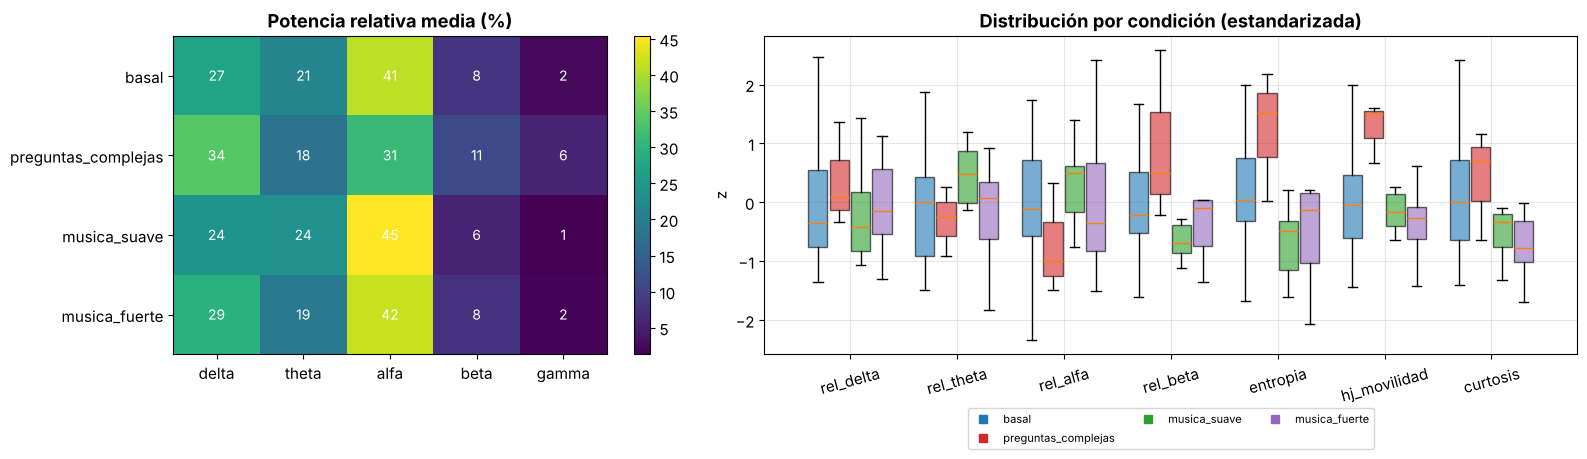

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})
rel = tabla.groupby("clase")[[f"rel_{b}" for b in BANDAS]].mean().reindex(CLASES) * 100
im = ax[0].imshow(rel.values, cmap="viridis", aspect="auto")
ax[0].set_xticks(range(len(BANDAS))); ax[0].set_xticklabels(BANDAS); ax[0].set_yticks(range(len(CLASES))); ax[0].set_yticklabels(CLASES)
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        ax[0].text(j, i, f"{rel.values[i, j]:.0f}", ha="center", va="center", color="w", fontsize=10)
ax[0].set_title("Potencia relativa media (%)"); ax[0].grid(False); plt.colorbar(im, ax=ax[0])

sel = ["rel_delta", "rel_theta", "rel_alfa", "rel_beta", "entropia", "hj_movilidad", "curtosis"]
z = (tabla[sel] - tabla[sel].mean()) / tabla[sel].std()
ancho = 0.8 / len(CLASES)
for j, c in enumerate(CLASES):
    pos = np.arange(len(sel)) + (j - (len(CLASES) - 1) / 2) * ancho
    bp = ax[1].boxplot([z[tabla.clase == c][s] for s in sel], positions=pos, widths=ancho*0.9,
                       patch_artist=True, showfliers=False)
    for caja in bp["boxes"]:
        caja.set_facecolor(COLOR.get(c, "gray")); caja.set_alpha(0.6)
    ax[1].plot([], [], "s", color=COLOR.get(c, "gray"), label=c)
ax[1].set_xticks(np.arange(len(sel))); ax[1].set_xticklabels(sel, rotation=15)
ax[1].set_ylabel("z"); ax[1].set_title("Distribución por condición (estandarizada)")
ax[1].legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout(); plt.show()

### ✍️ Pregunta B.3
1. ¿Qué condición tiene más potencia **delta**? ¿Qué condición tiene la **entropía espectral** más alta?
2. ¿Qué dos o tres características parecen separar mejor las condiciones?

**Respuesta B.3**

1. La que tiene más **delta** es **preguntas complejas** (34 % en promedio por época), seguida de música fuerte (29 %). La **entropía espectral más alta** también es la de preguntas complejas (**0.734**): su potencia está más repartida, con más beta (11 %) y gamma (6 %) que las demás. Hay que tener en cuenta que preguntas complejas solo tiene **3 épocas válidas**, así que estos promedios son poco confiables.
2. Según el mapa de calor y los boxplots:
   - **`entropia`** y **`hj_movilidad`** separan claramente preguntas complejas del resto.
   - **`rel_beta`** también es más alta en preguntas complejas.
   - **`rel_alfa`** es más alta en música suave (45 %) y música fuerte (42 %) que en preguntas complejas (31 %).

   En cambio, basal, música suave y música fuerte se parecen mucho entre sí en casi todas las características, y sus cajas se superponen.

<a id="B8"></a>
## B.8 Clasificación y una advertencia importante

Usamos los mismos cinco algoritmos del Laboratorio 11 (Árbol de Decisión, Regresión Logística, Random Forest, KNN y SVM) y la misma regla para **no hacer trampa**: las épocas se agrupan en **bloques de 10 s** y cada bloque va entero a entrenamiento o a prueba (`StratifiedGroupKFold`).

In [22]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

MODELOS = {
    "Árbol de Decisión":   lambda: DecisionTreeClassifier(max_depth=5, random_state=0),
    "Regresión Logística": lambda: LogisticRegression(max_iter=3000),
    "Random Forest":       lambda: RandomForestClassifier(n_estimators=200, random_state=0),
    "KNN (k=5)":           lambda: KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)":           lambda: SVC(kernel="rbf"),
}
nuevo_modelo = lambda nombre: make_pipeline(StandardScaler(), MODELOS[nombre]())

def esquema_validacion(tabla, objetivo="clase"):
    grupos = (tabla["archivo"] + "_b" + (tabla["t"] // 10).astype(int).astype(str)).to_numpy()
    n = int(min(5, tabla.assign(g=grupos).groupby(objetivo)["g"].nunique().min()))
    assert n >= 2, "Se necesitan al menos 2 bloques de 10 s por clase."
    return StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=0), grupos, n

def comparar_modelos(tabla, columnas, objetivo="clase"):
    cv, grupos, _ = esquema_validacion(tabla, objetivo)
    filas = []
    for nombre in MODELOS:
        s = cross_validate(nuevo_modelo(nombre), tabla[columnas].to_numpy(), tabla[objetivo].to_numpy(),
                           cv=cv, groups=grupos, scoring=["accuracy", "f1_macro"])
        filas.append({"Modelo": nombre, "Exactitud": s["test_accuracy"].mean(),
                      "F1 macro": s["test_f1_macro"].mean(), "± F1": s["test_f1_macro"].std()})
    return pd.DataFrame(filas).set_index("Modelo")

_, grupos, n_pl = esquema_validacion(tabla)
print(f"{len(tabla)} épocas | {len(np.unique(grupos))} bloques | {n_pl} pliegues | {len(CLASES)} clases → azar = {1/len(CLASES):.2f}")
resultados = comparar_modelos(tabla, CARACTERISTICAS)
display(resultados.round(3))

55 épocas | 19 bloques | 2 pliegues | 4 clases → azar = 0.25


,Exactitud,F1 macro,± F1
Modelo,,,
Árbol de Decisión,0.491,0.320,0.062
Regresión Logística,0.508,0.314,0.044
Random Forest,0.654,0.287,0.013
KNN (k=5),0.691,0.204,0.002
SVM (RBF),0.691,0.204,0.002


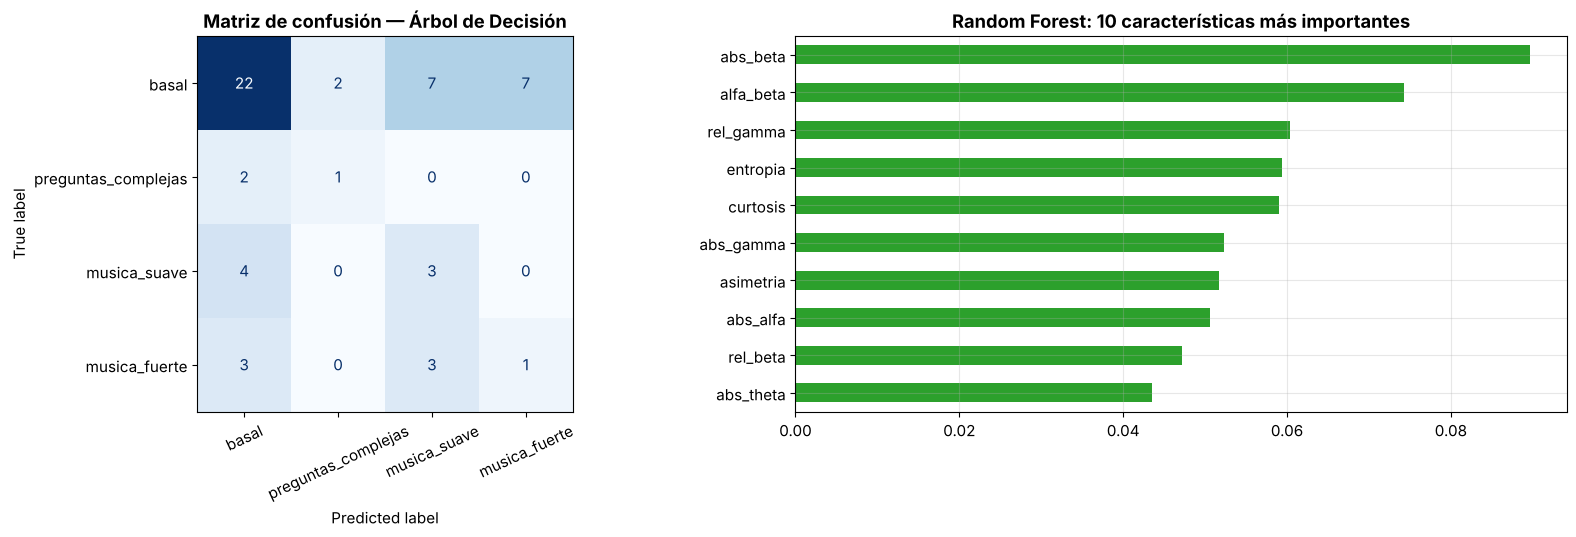

In [23]:
mejor = resultados["F1 macro"].idxmax()
cv, grupos, _ = esquema_validacion(tabla)
y = tabla["clase"].to_numpy()
y_pred = cross_val_predict(nuevo_modelo(mejor), tabla[CARACTERISTICAS].to_numpy(), y, cv=cv, groups=grupos)
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 1]})
ConfusionMatrixDisplay.from_predictions(y, y_pred, labels=CLASES, cmap="Blues", ax=ax[0], colorbar=False,
                                        xticks_rotation=25)
ax[0].set_title(f"Matriz de confusión — {mejor}"); ax[0].grid(False)
rf = nuevo_modelo("Random Forest").fit(tabla[CARACTERISTICAS].to_numpy(), y)
imp = pd.Series(rf[-1].feature_importances_, index=CARACTERISTICAS).sort_values()
imp.tail(10).plot.barh(ax=ax[1], color="tab:green"); ax[1].set_title("Random Forest: 10 características más importantes")
plt.tight_layout(); plt.show()

🔎 **Verificación adicional:** predicciones del mejor modelo desglosadas por archivo.

In [24]:
# 🔎 Verificación: ¿qué archivos producen los errores de la matriz de confusión?
display(pd.crosstab(tabla["archivo"] + " [" + tabla["dispositivo"] + "]", pd.Series(y_pred, name="predicción"))
        .reindex(columns=CLASES, fill_value=0))

predicción,basal,preguntas_complejas,musica_suave,musica_fuerte
row_0,,,,
Linea_basal_y_apertura_cierre_de_ojos_eeg.txt [2A:08],22,2,7,7
musica_fuerte_eeg.txt [2A:08],3,0,3,1
musica_suave_eeg.txt [2A:08],4,0,3,0
preguntas_complejas_eeg.txt [2A:08],2,1,0,0


### ⚠️ La advertencia: ¿estamos clasificando condiciones o dispositivos?
En la guía de referencia se usaron **dos BITalino distintos**. En nuestro caso **todos los registros se hicieron con el mismo equipo (2A:08)**, así que esta prueba no aplica, pero la dejamos para comprobarlo. Si las condiciones están repartidas de forma desigual entre dispositivos, el clasificador podría estar aprendiendo **qué equipo se usó** y no **qué estaba haciendo el cerebro**. A esto se le llama **variable de confusión** (*confound*).

**Prueba:** usamos las mismas características para predecir el **dispositivo**. Si lo predice casi perfecto, las características llevan una "huella" del equipo.

In [25]:
reparto = pd.crosstab(tabla["clase"], tabla["dispositivo"]).reindex(CLASES)
display(reparto.rename_axis(index="condición", columns="dispositivo"))
if tabla["dispositivo"].nunique() > 1:
    res_disp = comparar_modelos(tabla, CARACTERISTICAS, objetivo="dispositivo")
    print("¿Se puede predecir el DISPOSITIVO a partir de las características?")
    display(res_disp[["F1 macro", "± F1"]].round(3))
else:
    print("Solo hay un dispositivo: no aplica.")

dispositivo,2A:08
condición,
basal,38
preguntas_complejas,3
musica_suave,7
musica_fuerte,7


Solo hay un dispositivo: no aplica.


### ✍️ Pregunta B.4
1. ¿Qué modelo obtuvo el mejor F1? ¿Qué condiciones se confunden más en la matriz de confusión?
2. ¿Qué características usó más el Random Forest? ¿Tienen sentido fisiológico o podrían reflejar diferencias técnicas?
3. ¿Qué tan bien se predice el **dispositivo**? Mirando la tabla de reparto, ¿qué condiciones están "atadas" a un solo dispositivo? ¿Qué implica esto para interpretar el resultado de la clasificación?

**Respuesta B.4**

1. El mejor F1 fue el del **Árbol de Decisión: 0.320 ± 0.062**, seguido de Regresión Logística (0.314). El azar es 0.25, así que **casi no supera el azar**. KNN y SVM sacan F1 = 0.204, pero exactitud de 0.691: eso pasa porque predicen casi todo como "basal", que tiene 38 de las 55 épocas. Por eso aquí la exactitud engaña y el F1 macro es más justo. En la matriz de confusión, la basal acierta 22 de 38, pero **7 épocas se confunden con música suave y 7 con música fuerte**. A su vez, las músicas se confunden con la basal y entre ellas (música fuerte acierta solo 1 de 7).
2. Las más importantes para el Random Forest fueron **`abs_beta`, `alfa_beta`, `rel_gamma`, `entropia` y `curtosis`**. Algunas tienen sentido fisiológico, como el cociente alfa/beta, que se relaciona con relajación frente a alerta. Pero `rel_gamma`, `entropia` y `curtosis` también pueden reflejar **artefactos musculares o la saturación**, más que actividad cerebral. Igual, con tan pocos datos la importancia no es muy confiable.
3. No se puede probar porque **usamos un solo dispositivo** (2A:08 en las cuatro condiciones), así que aquí el equipo no es una variable de confusión. Pero hay otras: la **cantidad de épocas** está muy desbalanceada (38 basales contra 3, 7 y 7), las músicas se grabaron al final y casi seguidas, y preguntas complejas está casi toda saturada. **Conclusión:** con nuestros datos el modelo no logra reconocer la condición, y el problema principal es que hay muy pocas épocas válidas, no el dispositivo.

<a id="B9"></a>
## B.9 Conclusiones de la Parte B

| Etapa | Idea clave |
|---|---|
| Filtrado | Diezmado 1000 → 100 Hz con antialiasing (quita los 60 Hz) y pasa-banda 1–45 Hz. En nuestros datos no hizo falta notch |
| Ritmos | La potencia relativa por banda resume el estado. En nuestros datos la alfa (8.5 Hz) sí se ve y baja al abrir los ojos |
| ICA | Separa fuentes independientes. Con un canal se usa **Wavelet-ICA**: corrige los transitorios bruscos y elimina la interferencia de red, pero no separa artefactos continuos (parpadeo rítmico, masticación) que se superponen a las bandas del EEG |
| Normalización y épocas | El z-score facilita comparar, pero borra la amplitud. Se rechazan épocas saturadas |
| Características | 22 por época: bandas, cocientes, espectrales, Hjorth y estadísticas |
| Clasificación | Con pocas épocas válidas (por la saturación) el F1 queda cerca del azar. Un F1 alto tampoco garantizaría que se reconoce la fisiología: hay que descartar variables de confusión |

[⬆️ Volver al índice](#indice)

---
<a id="cuestionario"></a>
# 📝 Cuestionario final: experimenta con tus datos

La función `experimento(...)` repite la Parte B con los parámetros que elijas:

```python
experimento(condiciones=None,    # None = todas, o una lista: ["musica_suave", "musica_fuerte"]
            usar_ica=True,       # aplicar o no la limpieza con Wavelet-ICA
            notch=NOTCH_HZ,      # 40, 60 o None
            quitar_lineas=True,  # notch angosto en las líneas de interferencia detectadas en A.4
            normalizar=False,    # z-score de cada registro
            epoca_s=2,           # duración de las épocas en segundos
            rechazar_saturadas=True,  # descartar las épocas con saturación
            objetivo="clase")    # "clase" (condición) o "dispositivo"
```

Devuelve `(resultados, tabla, resumen)`.

In [26]:
def experimento(condiciones=None, usar_ica=True, notch=NOTCH_HZ, quitar_lineas=QUITAR_LINEAS, normalizar=False,
                epoca_s=2, objetivo="clase", rechazar_saturadas=True, columnas=None, mostrar=True):
    archivos = [a for a in senales if condiciones is None or condicion_desde_nombre(a) in condiciones]
    if len({condicion_desde_nombre(a) for a in archivos}) < 2:
        print(f"⚠️ No hay al menos 2 condiciones disponibles entre {condiciones}.")
        return None, None, None
    resumen = []
    for a in archivos:
        r = senales[a]
        r["exp"] = filtrar_eeg(r["eeg_uV"][i0:], notch=notch, lineas=lineas_de(a, quitar_lineas))
        n_red = n_trans = 0
        if usar_ica:
            r["exp"], d = ica_un_canal(r["exp"])
            n_red = int((d["metricas"]["acción"] == "eliminar (red)").sum())
            n_trans = int((d["metricas"]["acción"] == "corregir (transitorios)").sum())
        f, P = psd(r["exp"])
        resumen.append({"archivo": a, "ICs de red eliminadas": n_red, "ICs con transitorios corregidas": n_trans,
                        "pico 40 Hz tras procesar": round(pico_relativo(f, P), 1)})
    tab = construir_tabla(epoca_s, normalizar, "exp", archivos, rechazar_saturadas)
    cols = CARACTERISTICAS if columnas is None else columnas
    try:
        res = comparar_modelos(tab, cols, objetivo)
    except (AssertionError, ValueError) as e:
        res = None
        print(f"⚠️ No se pudo clasificar: {e}")
    resumen = pd.DataFrame(resumen).merge(tab.groupby("archivo").size().rename("épocas").reset_index(), on="archivo")
    if mostrar:
        print(f"▶ condiciones={condiciones or 'todas'} | ICA={usar_ica} | notch={notch} | líneas={quitar_lineas} | normalizar={normalizar} | "
              f"época={epoca_s} s | objetivo={objetivo}")
        display(resumen)
        if res is not None:
            display(res[["F1 macro", "± F1"]].T.round(3))
    return res, tab, resumen

print("✅ Función experimento() lista.")

✅ Función experimento() lista.


### Pregunta 1 — ¿Se distingue la música suave de la fuerte?
*(En nuestros datos las músicas se llaman "suave" y "fuerte".)* Ejecuta `experimento(["musica_suave", "musica_fuerte"])`. Ambas se grabaron con el **mismo dispositivo**, así que aquí no hay confusión por equipo. ¿Qué F1 obtienes? Usando la tabla devuelta, ¿qué banda cambia más entre ambas?

### Pregunta 2 — ¿Ayuda el ICA?
Compara `experimento(usar_ica=True)` con `experimento(usar_ica=False)`. ¿Cambia el F1? En la tabla devuelta, compara el promedio de `curtosis` y `pico_a_pico` de `preguntas_complejas` (nuestro registro con más artefactos; no tenemos parpadeo/masticación) con y sin ICA. Repite la comparación con `rechazar_saturadas=False`. ¿Cuándo se nota más el efecto del ICA? ¿Por qué?

### Pregunta 3 — ¿Qué pasa si no quitamos las interferencias?
a) Para aislar el efecto del notch, desactiva el filtrado de líneas angostas (`quitar_lineas=False`). Compara `experimento(notch=40, quitar_lineas=False)`, `experimento(notch=60, quitar_lineas=False)` y `experimento(notch=None, quitar_lineas=False)`. Mira *pico 40 Hz tras procesar*, *ICs de red eliminadas*, el promedio de `rel_gamma` por condición y el F1. ¿Sirve el notch de 60 Hz? Sin notch, ¿el ICA detecta la interferencia por sí solo? ¿Por qué podría **subir** el F1 si dejamos la interferencia?
b) Ejecuta `experimento(quitar_lineas=False)`. ¿Cómo cambian `rel_theta` y `f_pico` en los registros basales del dispositivo con líneas angostas?

*(En nuestro caso lo hicimos al revés: como en el análisis principal usamos `QUITAR_LINEAS = False`, comparamos con `experimento(quitar_lineas=True)` y vemos qué pasa en las músicas, que es donde se detectaron las líneas de 8.4 Hz.)*

### Pregunta 4 — Normalizar, ¿ayuda o perjudica?
Ejecuta `experimento(normalizar=True)` y compáralo con `normalizar=False`. *(La parte del dispositivo no aplica: usamos un solo BITalino.)* ¿Qué pasa con la capacidad de reconocer la condición? ¿Qué características dejan de ser útiles al normalizar?

### Pregunta 5 — Duración de la época
Prueba `epoca_s=1`, `2` y `4`. ¿Cómo cambia el número de épocas, la resolución en frecuencia ($1/T$) y el F1? ¿Qué duración elegirías?

In [27]:
# Pregunta 1 — Música suave vs fuerte (mismo dispositivo)
res_m, tab_m, resu_m = experimento(["musica_suave", "musica_fuerte"])
bandas_rel = [f"rel_{b}" for b in BANDAS]
medias = tab_m.groupby("clase")[bandas_rel + ["entropia", "f_pico", "theta_beta", "alfa_beta"]].mean()
medias[bandas_rel] *= 100
display(medias.T.rename(index={f"rel_{b}": f"rel_{b} (%)" for b in BANDAS}).round(3))

▶ condiciones=['musica_suave', 'musica_fuerte'] | ICA=True | notch=None | líneas=False | normalizar=False | época=2 s | objetivo=clase


,archivo,ICs de red eliminadas,ICs con transitorios corregidas,pico 40 Hz tras procesar,épocas
0,musica_suave_eeg.txt,0,0,0.7,7
1,musica_fuerte_eeg.txt,0,0,1.3,7


Modelo,Árbol de Decisión,Regresión Logística,Random Forest,KNN (k=5),SVM (RBF)
F1 macro,0.300,0.473,0.439,0.361,0.302
± F1,0.098,0.232,0.106,0.171,0.022


clase,musica_fuerte,musica_suave
rel_delta (%),29.497,24.119
rel_theta (%),19.141,23.602
rel_alfa (%),41.788,45.448
rel_beta (%),7.812,5.514
rel_gamma (%),1.762,1.318
entropia,0.635,0.608
f_pico,6.643,7.071
theta_beta,2.950,4.389
alfa_beta,6.602,8.497


**Respuesta 1 — Música suave vs. música fuerte**

Ambas se grabaron con el mismo equipo y con menos de 1 minuto de diferencia. El F1 va de **0.300** (Árbol de Decisión y SVM) a **0.473** (Regresión Logística), y como son 2 clases el azar es 0.5. O sea, **no se distinguen**; además, la variación entre pliegues es grande (hasta ±0.23).

Las diferencias entre bandas son pequeñas:
- música suave: más **alfa** (45.4 % vs 41.8 %) y más **theta** (23.6 % vs 19.1 %);
- música fuerte: más **delta** (29.5 % vs 24.1 %) y algo más de **beta** (7.8 % vs 5.5 %).

La banda que más cambia es la **delta**. Tendría algo de sentido que la música suave dé más alfa (más relajación) y la fuerte un poco más de beta (más activación), pero con solo **7 épocas por música** y una sola grabación de cada una no podemos concluir nada.

In [28]:
# Pregunta 2 — Con y sin ICA, rechazando o no las épocas saturadas
filas_f1, comp = {}, {}
cols = ["rel_delta", "rel_gamma", "curtosis", "pico_a_pico"]
for rech in [True, False]:
    for ica_on in [True, False]:
        res_x, tab_x, _ = experimento(usar_ica=ica_on, rechazar_saturadas=rech, mostrar=False)
        nombre = f"{'con' if ica_on else 'sin'} ICA | {'rechazando' if rech else 'SIN rechazar'} saturadas"
        filas_f1[nombre] = res_x["F1 macro"]
        comp[nombre] = tab_x[tab_x.clase == "preguntas_complejas"][cols].mean()
        comp[nombre]["épocas de preguntas"] = (tab_x.clase == "preguntas_complejas").sum()
display(pd.DataFrame(filas_f1).round(3))
display(pd.DataFrame(comp).round(3))

,con ICA | rechazando saturadas,sin ICA | rechazando saturadas,con ICA | SIN rechazar saturadas,sin ICA | SIN rechazar saturadas
Modelo,,,,
Árbol de Decisión,0.320,0.320,0.433,0.479
Regresión Logística,0.314,0.265,0.405,0.417
Random Forest,0.287,0.287,0.384,0.385
KNN (k=5),0.204,0.204,0.360,0.366
SVM (RBF),0.204,0.204,0.373,0.381


,con ICA | rechazando saturadas,sin ICA | rechazando saturadas,con ICA | SIN rechazar saturadas,sin ICA | SIN rechazar saturadas
rel_delta,0.338,0.344,0.678,0.670
rel_gamma,0.057,0.043,0.016,0.014
curtosis,0.085,0.132,-0.222,-0.272
pico_a_pico,47.965,47.959,86.771,84.798
épocas de preguntas,3.000,3.000,87.000,87.000


**Respuesta 2 — ¿Ayuda el ICA?**

| Configuración | Mejor F1 | Épocas de preguntas | Curtosis media | Pico a pico medio (µV) |
|---|---|---|---|---|
| Con ICA, rechazando saturadas | 0.320 | 3 | 0.085 | 47.97 |
| Sin ICA, rechazando saturadas | 0.320 | 3 | 0.132 | 47.96 |
| Con ICA, **sin** rechazar saturadas | 0.433 | 87 | −0.222 | 86.77 |
| Sin ICA, **sin** rechazar saturadas | 0.479 | 87 | −0.272 | 84.80 |

- **Rechazando las saturadas**, el ICA casi no cambia nada: el mejor F1 es el mismo (solo cambia la Regresión Logística, de 0.265 a 0.314) y el pico a pico es igual. Solo quedan 3 épocas de preguntas complejas.
- **Sin rechazar**, el F1 sube, pero no por el ICA (sin ICA incluso es un poco mayor). Sube porque las épocas saturadas de preguntas complejas tienen un pico a pico enorme (~85 µV contra ~48), y el modelo usa eso para reconocerlas. Es decir, **usa el artefacto como pista**.
- El efecto del ICA se nota un poco más sin rechazar (curtosis −0.272 → −0.222), pero es pequeño.

**Conclusión:** en nuestros datos el ICA de un canal ayuda poco, porque el problema principal es la **saturación**, y una señal recortada no se puede reconstruir.

In [29]:
# Pregunta 3a — ¿Notch en 40 Hz, en 60 Hz o ninguno? (sin el filtrado de líneas angostas, para aislar el efecto)
filas, gam, f1 = [], {}, {}
for nombre, kw in [("notch 40 Hz", dict(notch=40)), ("notch 60 Hz", dict(notch=60)), ("sin notch", dict(notch=None))]:
    res_n, tab_n, resu_n = experimento(quitar_lineas=False, mostrar=False, **kw)
    gam[nombre] = tab_n.groupby("clase")["rel_gamma"].mean() * 100
    f1[nombre] = res_n["F1 macro"]
    for _, f_ in resu_n.iterrows():
        filas.append({"configuración": nombre, "archivo": f_["archivo"],
                      "ICs de red eliminadas": f_["ICs de red eliminadas"],
                      "pico 40 Hz tras procesar": f_["pico 40 Hz tras procesar"]})
display(pd.DataFrame(filas).pivot(index="archivo", columns="configuración").loc[tabla_lectura.archivo])
display(pd.DataFrame(gam).reindex(CLASES).round(1).rename_axis("rel_gamma (%)"))
display(pd.DataFrame(f1).round(3).rename_axis("F1 macro"))

⚠️ Notch de 60 Hz imposible: está por encima de Nyquist (50 Hz). No se aplicó.
⚠️ Notch de 60 Hz imposible: está por encima de Nyquist (50 Hz). No se aplicó.
⚠️ Notch de 60 Hz imposible: está por encima de Nyquist (50 Hz). No se aplicó.
⚠️ Notch de 60 Hz imposible: está por encima de Nyquist (50 Hz). No se aplicó.


ICs de red eliminadas  \
configuración                                           notch 40 Hz   
archivo                                                               
Linea_basal_y_apertura_cierre_de_ojos_eeg.txt                     0   
preguntas_complejas_eeg.txt                                       0   
musica_suave_eeg.txt                                              0   
musica_fuerte_eeg.txt                                             0   

                                                                     \
configuración                                 notch 60 Hz sin notch   
archivo                                                               
Linea_basal_y_apertura_cierre_de_ojos_eeg.txt           0         0   
preguntas_complejas_eeg.txt                             0         0   
musica_suave_eeg.txt                                    0         0   
musica_fuerte_eeg.txt                                   0         0   

                                              pico 40 Hz tras procesar  \
configuración                                              notch 40 Hz   
archivo                                                                  
Linea_basal_y_apertura_cierre_de_ojos_eeg.txt                      0.0   
preguntas_complejas_eeg.txt                                        0.7   
musica_suave_eeg.txt                                               0.0   
musica_fuerte_eeg.txt                                              0.0   

                                                                     
configuración                                 notch 60 Hz sin notch  
archivo                                                              
Linea_basal_y_apertura_cierre_de_ojos_eeg.txt         1.3       1.3  
preguntas_complejas_eeg.txt                           1.6       1.6  
musica_suave_eeg.txt                                  0.7       0.7  
musica_fuerte_eeg.txt                                 1.3       1.3

,notch 40 Hz,notch 60 Hz,sin notch
rel_gamma (%),,,
basal,1.7,2.2,2.2
preguntas_complejas,3.1,5.7,5.7
musica_suave,1.0,1.3,1.3
musica_fuerte,1.3,1.8,1.8


,notch 40 Hz,notch 60 Hz,sin notch
F1 macro,,,
Árbol de Decisión,0.290,0.320,0.320
Regresión Logística,0.261,0.314,0.314
Random Forest,0.293,0.287,0.287
KNN (k=5),0.204,0.204,0.204
SVM (RBF),0.204,0.204,0.204


**Respuesta 3a — ¿Notch en 40 Hz, en 60 Hz o ninguno?**

- **El notch de 60 Hz no se puede aplicar** sobre la señal diezmada: el cuaderno avisa que 60 Hz está por encima de Nyquist (50 Hz) y no lo aplica. Por eso sus resultados son **iguales** a no usar notch.
- **Sin notch, el ICA no elimina ninguna componente de red** en ningún archivo (0 en los 4), porque no hay interferencia que quitar: el pico de 40 Hz tras procesar queda entre 0.7 y 1.6 veces, que es nada. El antialiasing del diezmado ya quitó los 60 Hz.
- **Con notch en 40 Hz** baja `rel_gamma` (preguntas complejas de 5.7 % a 3.1 %, basal de 2.2 % a 1.7 %). No está quitando interferencia, sino **actividad real entre 38 y 42 Hz**. Por eso en nuestro caso es mejor no usarlo.
- El F1 casi no cambia (0.290–0.320), dentro de la variación.

*(Conceptual)* El F1 podría subir si dejamos una interferencia cuando esta es distinta en cada condición. En nuestros datos el pico de 60 Hz original era mucho mayor en preguntas complejas (88 veces) y en música fuerte (65) que en la basal (4.7). Si no lo hubiéramos quitado, el modelo podría reconocer la condición por la interferencia y no por el cerebro.

In [30]:
# Pregunta 3b — ¿Qué pasa si SÍ quitamos las "líneas angostas" que detectó A.4?
# (en nuestro análisis principal QUITAR_LINEAS = False, porque las líneas de 8.4 Hz parecen ser la alfa)
res_l, tab_l, _ = experimento(quitar_lineas=True, mostrar=False)
comp = pd.DataFrame({
    "rel_alfa (%) sin quitar líneas": tabla.groupby("archivo")["rel_alfa"].mean() * 100,
    "rel_alfa (%) quitando líneas": tab_l.groupby("archivo")["rel_alfa"].mean() * 100,
    "rel_theta (%) sin quitar líneas": tabla.groupby("archivo")["rel_theta"].mean() * 100,
    "rel_theta (%) quitando líneas": tab_l.groupby("archivo")["rel_theta"].mean() * 100,
    "f_pico sin quitar líneas": tabla.groupby("archivo")["f_pico"].median(),
    "f_pico quitando líneas": tab_l.groupby("archivo")["f_pico"].median()}).loc[tabla_lectura.archivo]
display(comp.round(1))
print(f"Mejor F1 quitando líneas: {res_l['F1 macro'].max():.3f}  (sin quitarlas: {resultados['F1 macro'].max():.3f})")

,rel_alfa (%) sin quitar líneas,rel_alfa (%) quitando líneas,rel_theta (%) sin quitar líneas,rel_theta (%) quitando líneas,f_pico sin quitar líneas,f_pico quitando líneas
archivo,,,,,,
Linea_basal_y_apertura_cierre_de_ojos_eeg.txt,41.3,41.3,21.3,21.3,8.5,8.5
preguntas_complejas_eeg.txt,31.0,31.0,18.1,18.1,2.0,2.0
musica_suave_eeg.txt,45.4,30.4,23.6,29.7,8.0,7.0
musica_fuerte_eeg.txt,41.8,33.6,19.1,21.7,8.0,7.5


Mejor F1 quitando líneas: 0.357  (sin quitarlas: 0.320)


**Respuesta 3b — ¿Qué pasa si quitamos las "líneas angostas"?**

| Registro | rel_alfa sin quitar / quitando | rel_theta sin quitar / quitando | f_pico sin quitar / quitando |
|---|---|---|---|
| música suave | 45.4 % / **30.4 %** | 23.6 % / **29.7 %** | 8.0 / **7.0** Hz |
| música fuerte | 41.8 % / **33.6 %** | 19.1 % / **21.7 %** | 8.0 / **7.5** Hz |
| basal y preguntas | sin cambios (no tienen líneas detectadas) | | |

Si quitamos las "líneas" de 8.35–8.4 Hz, **la alfa de las músicas baja entre 8 y 15 puntos**, la theta sube en proporción y la frecuencia pico se mueve de 8 Hz a 7–7.5 Hz. O sea, el notch borra justo el **pico alfa del participante**, que coincide con el de la basal (8.5 Hz). El mejor F1 sube un poco (0.320 → 0.357), pero está dentro de la variación y las características dejan de ser interpretables. Por eso decidimos **no quitar esas líneas** (`QUITAR_LINEAS = False`). Es lo contrario de lo que pasó en la guía, donde las líneas sí eran interferencias.

In [31]:
# Pregunta 4 — Normalizar la señal (z-score por registro)
r_c0, t_c0, _ = experimento(normalizar=False, mostrar=False)
r_c1, t_c1, _ = experimento(normalizar=True, mostrar=False)
# (no probamos objetivo="dispositivo" porque todos nuestros registros son del mismo BITalino)
display(pd.DataFrame({"condición — sin normalizar": r_c0["F1 macro"], "condición — normalizada": r_c1["F1 macro"]}).round(3))
amp = ["desv_est", "hj_actividad", "pico_a_pico", "abs_alfa"]
display(pd.concat({"sin normalizar": t_c0.groupby("clase")[amp].mean(),
                   "normalizada": t_c1.groupby("clase")[amp].mean()}, axis=1).reindex(CLASES).round(2))

,condición — sin normalizar,condición — normalizada
Modelo,,
Árbol de Decisión,0.320,0.345
Regresión Logística,0.314,0.350
Random Forest,0.287,0.237
KNN (k=5),0.204,0.204
SVM (RBF),0.204,0.204


sin normalizar                                    \
                          desv_est hj_actividad pico_a_pico abs_alfa   
clase                                                                  
basal                         9.27         1.92       48.55     1.80   
preguntas_complejas           8.96         1.90       47.97     1.59   
musica_suave                  8.95         1.89       44.73     1.87   
musica_fuerte                 9.33         1.94       46.26     1.80   

                    normalizada                                    
                       desv_est hj_actividad pico_a_pico abs_alfa  
clase                                                              
basal                      0.72        -0.29        3.78    -0.42  
preguntas_complejas        0.44        -0.71        2.38    -1.02  
musica_suave               0.80        -0.21        3.99    -0.23  
musica_fuerte              0.89        -0.10        4.43    -0.24

**Respuesta 4 — ¿Normalizar ayuda o perjudica?**

| Modelo | F1 sin normalizar | F1 normalizada |
|---|---|---|
| Árbol de Decisión | 0.320 | 0.345 |
| Regresión Logística | 0.314 | 0.350 |
| Random Forest | 0.287 | 0.237 |
| KNN y SVM | 0.204 | 0.204 |

- Normalizar **no cambia mucho**: dos modelos suben un poco y Random Forest baja, pero todo sigue cerca del azar (0.25) y las diferencias son menores que la variación entre pliegues.
- La parte del dispositivo no aplica porque usamos un solo BITalino.

**Las características que dejan de ser útiles** son las de **amplitud absoluta**. Sin normalizar, `desv_est` iba de 8.95 a 9.33 µV y `pico_a_pico` de 44.7 a 48.5 µV. Normalizadas quedan en 0.44–0.89 y 2.4–4.4. En nuestros datos esas diferencias ya eran pequeñas desde antes, porque todos los registros son del mismo equipo. Por eso normalizar ni ayuda ni perjudica mucho.

In [32]:
# Pregunta 5 — Duración de la época
filas = []
for T in [1, 2, 4]:
    res_e, tab_e, _ = experimento(epoca_s=T, mostrar=False)
    if res_e is None:   # con épocas largas a veces no hay 2 bloques de 10 s por condición (preguntas complejas)
        filas.append({"época (s)": T, "resolución 1/T (Hz)": 1 / T, "épocas válidas": len(tab_e),
                      "mejor modelo": "no se pudo clasificar", "mejor F1": np.nan, "F1 promedio 5 modelos": np.nan})
        continue
    filas.append({"época (s)": T, "resolución 1/T (Hz)": 1 / T, "épocas válidas": len(tab_e),
                  "mejor modelo": res_e["F1 macro"].idxmax(), "mejor F1": round(res_e["F1 macro"].max(), 3),
                  "F1 promedio 5 modelos": round(res_e["F1 macro"].mean(), 3)})
display(pd.DataFrame(filas))
# épocas válidas por condición con cada duración
display(pd.DataFrame({T: experimento(epoca_s=T, mostrar=False)[1].groupby("clase").size() for T in [1, 2, 4]}).reindex(CLASES).rename_axis("épocas válidas por condición"))

⚠️ No se pudo clasificar: Se necesitan al menos 2 bloques de 10 s por clase.


,época (s),resolución 1/T (Hz),épocas válidas,mejor modelo,mejor F1,F1 promedio 5 modelos
0,1,1.00,155,KNN (k=5),0.25,0.216
1,2,0.50,55,Árbol de Decisión,0.32,0.266
2,4,0.25,18,no se pudo clasificar,NaN,NaN


⚠️ No se pudo clasificar: Se necesitan al menos 2 bloques de 10 s por clase.


,1,2,4
épocas válidas por condición,,,
basal,103,38,15
preguntas_complejas,13,3,1
musica_suave,20,7,1
musica_fuerte,19,7,1


**Respuesta 5 — Duración de la época**

| Época | Resolución 1/T | Épocas válidas | Mejor F1 | F1 promedio de los 5 modelos |
|---|---|---|---|---|
| 1 s | 1.00 Hz | 155 | 0.250 (KNN) | 0.216 |
| 2 s | 0.50 Hz | 55 | 0.320 (Árbol) | 0.266 |
| 4 s | 0.25 Hz | 18 | no se pudo clasificar | – |

- Con épocas **más largas** mejora la resolución en frecuencia, pero se rechazan muchas más épocas, porque es más probable que una época larga tenga alguna muestra saturada. Con 4 s quedan solo **1 época** de preguntas complejas, 1 de música suave y 1 de música fuerte, y no alcanzan los 2 bloques de 10 s por clase para la validación.
- Con **1 s** hay más épocas (155), pero el F1 no mejora y la resolución de 1 Hz es muy gruesa para bandas angostas como la theta.

**Elegimos 2 s**, porque es el término medio: resolución de 0.5 Hz y suficientes épocas para que funcione la validación.

---
## Conclusión general del laboratorio (grupo 11)

1. **Revisar los datos fue lo más importante.** Encontramos que nuestras señales estaban a 1000 Hz (no a 100 Hz como en la guía), que tenían interferencia de 60 Hz y, sobre todo, mucha **saturación**: 29 % en preguntas complejas. Con la regla de rechazar las épocas saturadas, ese registro quedó con solo 3 épocas útiles.
2. **Filtrado:** al diezmar a 100 Hz con `decimate`, el filtro antialiasing quita los 60 Hz y no aparece el alias de 40 Hz, así que no necesitamos notch. También vimos que el detector de "líneas angostas" puede confundir la **alfa real** con una interferencia. Revisarlo antes de filtrar evitó que borráramos la alfa.
3. **Ritmos:** a diferencia del grupo de la guía, en nuestros datos **sí se ve la alfa** (pico en 8.5 Hz), dominante en la basal y en las músicas. En la segunda parte del registro basal (apertura/cierre de ojos) la alfa baja y sube la delta, lo que es compatible con el bloqueo alfa y los movimientos oculares.
4. **ICA:** con un solo canal, el Wavelet-ICA solo corrigió 2 componentes con transitorios en preguntas complejas (2.2 % de la varianza). No puede arreglar la saturación ni separar artefactos continuos.
5. **Clasificación:** el mejor F1 fue 0.320 para 4 condiciones (azar 0.25), así que con nuestros datos **no se pueden reconocer las condiciones**. La causa principal es que hay pocas épocas válidas y están muy desbalanceadas. Además, comprobamos que dejar artefactos (no rechazar épocas saturadas) **sube** el F1 de forma engañosa.
6. **Para la próxima adquisición:** revisar la colocación y el contacto de los electrodos para que la señal no sature (sobre todo en la tarea de preguntas), marcar en qué momento se abren y cierran los ojos, y grabar varias repeticiones de cada condición con duraciones parecidas.

---
<a id="entregables"></a>
# 📦 Entregables y referencias

### Entregables
1. Este cuaderno ejecutado **con tus registros**, con todas las preguntas ✍️ respondidas.
2. El cuestionario final con tus experimentos.
3. El archivo `caracteristicas_eeg.csv` (se genera en la celda siguiente).

### Referencias
1. L. De La Cruz, *Tratamiento de señal EEG* (diapositivas del curso), UPCH.
2. MNE-Python, *Removing muscle ICA components*. https://mne.tools/stable/auto_examples/preprocessing/muscle_ica.html
3. D. Dharmaprani et al., "A comparison of independent component analysis algorithms and measures to discriminate between EEG and artifact components", *IEEE EMBC*, 2016, pp. 825–828. doi: 10.1109/EMBC.2016.7590828
4. A. Hyvärinen y E. Oja, "Independent component analysis: algorithms and applications", *Neural Networks*, vol. 13, pp. 411–430, 2000.
5. N. P. Castellanos y V. A. Makarov, "Recovering EEG brain signals: Artifact suppression with wavelet enhanced independent component analysis", *J. Neurosci. Methods*, vol. 158, pp. 300–312, 2006.
6. B. Hjorth, "EEG analysis based on time domain properties", *Electroencephalogr. Clin. Neurophysiol.*, vol. 29, pp. 306–310, 1970.
7. P. D. Welch, "The use of fast Fourier transform for the estimation of power spectra", *IEEE Trans. Audio Electroacoust.*, vol. 15, pp. 70–73, 1967.
8. J. A. Urigüen y B. Garcia-Zapirain, "EEG artifact removal—state-of-the-art and guidelines", *J. Neural Eng.*, vol. 12, 031001, 2015.
9. PLUX Wireless Biosignals, *BITalino (r)evolution — EEG Sensor Datasheet* (fórmula de conversión).

[⬆️ Volver al índice](#indice)

In [33]:
tabla.to_csv("caracteristicas_eeg.csv", index=False)
print("✅ Archivo generado: caracteristicas_eeg.csv", tabla.shape)
try:
    from google.colab import files
    files.download("caracteristicas_eeg.csv")
except ImportError:
    pass

✅ Archivo generado: caracteristicas_eeg.csv (55, 26)
